# Trabajo del grupo 6, datos de las 5 grandes ligas europeas del fútbol
Alejandro Álvarez Segoviano e Ivo Reguero Ferrer

# 0. Importamos librerías

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr, pointbiserialr, chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import copy, warnings
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import recall_score, fbeta_score, roc_auc_score, accuracy_score, confusion_matrix, roc_curve, make_scorer, log_loss
from sklearn.base import BaseEstimator, ClassifierMixin
import sklearn

In [63]:
'''
ruta = Path().resolve().parent
ruta = ruta / "data" / "fulbo.csv"
ruta
''' # Se cambia, quita o deja en funcion de como pida leer los datos, del directorio directo, otra carpeta o etc...

'\nruta = Path().resolve().parent\nruta = ruta / "data" / "fulbo.csv"\nruta\n'

In [64]:
ruta = "fulbo.csv"

# 1. Primer vistazo a los datos y EDA

## 1.1 Mirada inicial

Vamos a comenzar leyendo los datos, observando de cuántas observaciones disponemos, cuántos atributos y de qué naturaleza, previo a la modelización para entender mejor la naturaleza de ellas, cómo se relacionan y si presentan limitaciones o sesgos, para hallar de que tipo son.

In [65]:
df = pd.read_csv(ruta,header=1,index_col="Rk") # para no agrupar por el tipo de variable

In [66]:
df.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches,-9999
Rk,,,,,,,,,,,,,,,,,,,,,
1,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,0,3,0,0.15,0.18,0.33,0.15,0.33,Matches,5bc43860
2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,4f504fcc
3,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,c103921a
4,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,0,0,0,0.26,0.00,0.26,0.26,0.26,Matches,29dd3b2e
5,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,138,...,0,1,0,0.00,0.00,0.00,0.00,0.00,Matches,7978cbf0


In [67]:
print(f"Disponemos de {df.shape[0]} jugadores y {df.shape[1]} atributos.")

Disponemos de 2839 jugadores y 26 atributos.


Esos 27 atributos son los siguientes :

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2839 entries, 1 to 2839
Data columns (total 26 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Player   2839 non-null   str    
 1   Nation   2836 non-null   str    
 2   Pos      2839 non-null   str    
 3   Squad    2839 non-null   str    
 4   Comp     2839 non-null   str    
 5   Age      2837 non-null   float64
 6   Born     2837 non-null   float64
 7   MP       2839 non-null   int64  
 8   Starts   2839 non-null   int64  
 9   Min      2839 non-null   int64  
 10  90s      2839 non-null   float64
 11  Gls      2839 non-null   int64  
 12  Ast      2839 non-null   int64  
 13  G+A      2839 non-null   int64  
 14  G-PK     2839 non-null   int64  
 15  PK       2839 non-null   int64  
 16  PKatt    2839 non-null   int64  
 17  CrdY     2839 non-null   int64  
 18  CrdR     2839 non-null   int64  
 19  Gls.1    2839 non-null   float64
 20  Ast.1    2839 non-null   float64
 21  G+A.1    2839 non-null   

Algunos atributos tienen nulos, de igual forma cada variable individualmente será revisada después por si hay nulos codificados.

La página web de la que provienen los datos posee un glosario que usaremos para poder explicar qué significa cada dato, en la siguiente sección lo usaremos.

## 1.2 Diccionario De Atributos

In [69]:
diccionario = {
    "Identificación": [
        ("Rk", "Posición en la tabla de FBref (sin valor analítico)"),
        ("Player", "Nombre del jugador"),
        ("Nation", "Nacionalidad (código de 3 letras, p. ej. es ESP)"),
        ("Pos", "Posición: GK, DF, MF, FW; puede combinar varias (MF,FW)"),
        ("Squad", "Club"),
        ("Comp", "Liga / competición"),
        ("Age", "Edad al inicio de la temporada"),
        ("Born", "Año de nacimiento"),
    ],
    "Participación": [
        ("MP", "Partidos jugados"),
        ("Starts", "Partidos como titular"),
        ("Min", "Minutos jugados"),
        ("90s", "Minutos / 90 (denominador de las tasas por 90)"),
    ],
    "Producción ofensiva (totales)": [
        ("Gls", "Goles"),
        ("Ast", "Asistencias"),
        ("G+A", "Goles + asistencias"),
        ("G-PK", "Goles sin contar penaltis"),
        ("PK", "Penaltis marcados"),
        ("PKatt", "Penaltis intentados"),
    ],
    "Disciplina": [
        ("CrdY", "Tarjetas amarillas"),
        ("CrdR", "Tarjetas rojas"),
    ],
    "Por 90 minutos (el sufijo .1 lo añade pandas)": [
        ("Gls.1", "Goles por 90 min"),
        ("Ast.1", "Asistencias por 90 min"),
        ("G+A.1", "Goles + asistencias por 90 min"),
        ("G-PK.1", "Goles sin penalti por 90 min"),
        ("G+A-PK", "(Goles sin penalti + asistencias) por 90 min"),
    ],
    "Otras": [
        ("Matches", "Enlace al detalle partido a partido (sin valor analítico)"),
        ("-9999", "ID de jugador"),
    ],
}

FONT = "18px"   # tamanio

html = f"<div style='font-size:{FONT}'>"
html += "<h2>Diccionario de variables (FBref · Standard Stats)</h2>"
for seccion, filas in diccionario.items():
    html += f"<h3>{seccion}</h3><table style='border-collapse:collapse;width:100%'>"
    html += "<tr><th style='text-align:left;padding:8px;border-bottom:2px solid #888'>Variable</th>"
    html += "<th style='text-align:left;padding:8px;border-bottom:2px solid #888'>Descripción</th></tr>"
    for var, desc in filas:
        html += (f"<tr><td style='padding:8px;border-bottom:1px solid #ccc'><code>{var}</code></td>"
                 f"<td style='padding:8px;border-bottom:1px solid #ccc'>{desc}</td></tr>")
    html += "</table>"

display(HTML(html))

Variable,Descripción
Rk,Posición en la tabla de FBref (sin valor analítico)
Player,Nombre del jugador
Nation,"Nacionalidad (código de 3 letras, p. ej. es ESP)"
Pos,"Posición: GK, DF, MF, FW; puede combinar varias (MF,FW)"
Squad,Club
Comp,Liga / competición
Age,Edad al inicio de la temporada
Born,Año de nacimiento
Variable,Descripción
MP,Partidos jugados


## 1.3 Calidad del dato

En este apartado vamos a evaluar la calidad de los datos, hablando en castellano esto es asegurarnos los datos sean coherentes, no estén duplicados (principalmente para evitar leakage), tratar posibles nulos entre otras situaciones.

Se comenzará analizando la presencia de nulos en el dataset

In [70]:
df.isnull().sum()

Player     0
Nation     3
Pos        0
Squad      0
Comp       0
Age        2
Born       2
MP         0
Starts     0
Min        0
90s        0
Gls        0
Ast        0
G+A        0
G-PK       0
PK         0
PKatt      0
CrdY       0
CrdR       0
Gls.1      0
Ast.1      0
G+A.1      0
G-PK.1     0
G+A-PK     0
Matches    0
-9999      0
dtype: int64

Se presencian nulos en las variables Age, Born y Nation

In [71]:
df[df["Nation"].isnull()]

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches,-9999
Rk,,,,,,,,,,,,,,,,,,,,,
1699,Nathan Mbala,NaN,MFFW,Metz,fr Ligue 1,17.0,2008.0,13,4,441,...,0,0,0,0.41,0.41,0.82,0.41,0.82,Matches,42754695
2005,Luis Orejuela,NaN,DF,Mallorca,es La Liga,NaN,NaN,1,1,90,...,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches,18e70be1
2631,Yael Trepy,NaN,FW,Cagliari,it Serie A,NaN,NaN,8,0,91,...,0,0,0,0.99,0.00,0.99,0.99,0.99,Matches,20c36c00


Apreciamos son tres casos a priori aislados, a excepción de los casos de Luis Orejuela y Yael Trepy, donde la falta de la fecha de nacimiento y edad tiene sentido, ya que a partir de una se podría estimar un proxy de la otra, sin embargo al carecer de ambas esa información se pierde

Debido a que son solo tres filas con faltantes la información faltante ha sido buscada y va a ser imputada.

Para el caso de Nathan Mbala este nulo tiene un significado, dado que al inspeccionar en internet hay informacion que se contradice, por una parte algunas páginas le atribuyen nacionalidad francesa mientras que otras le atribuyen nacionalidad de la república del congo, incluso llegan a contradecirse de en que lugar nació, por lo que se va a dejar como nulo para no introducir información no verificada

In [72]:
df.loc[df['Player'] == 'Luis Orejuela', ['Nation', 'Age', 'Born']] = ['es ESP', 18, 2007]
df.loc[df['Player'] == 'Yael Trepy', ['Nation', 'Age', 'Born']] = ['fr FRA', 19, 2006]

In [73]:
df.isnull().sum()

Player     0
Nation     1
Pos        0
Squad      0
Comp       0
Age        0
Born       0
MP         0
Starts     0
Min        0
90s        0
Gls        0
Ast        0
G+A        0
G-PK       0
PK         0
PKatt      0
CrdY       0
CrdR       0
Gls.1      0
Ast.1      0
G+A.1      0
G-PK.1     0
G+A-PK     0
Matches    0
-9999      0
dtype: int64

Una vez acabados con los nulos, se pasa a investigar la presencia de duplicados

In [74]:
print("Filas duplicadas exactas:", df.duplicated().sum())

por_nombre = df.groupby('Player')['-9999'].nunique()
homonimos = por_nombre[por_nombre > 1]
print("Nombres compartidos por IDs distintos:", len(homonimos))


Filas duplicadas exactas: 0
Nombres compartidos por IDs distintos: 4


¿Cuántos de ellos son la misma persona y cuantos son solo el mismo nombre?

In [75]:
nombres = df.groupby('Player').agg(
    filas=('Player', 'size'),
    n_ids=('-9999', 'nunique'),
    n_born=('Born', 'nunique'),
    n_nation=('Nation', 'nunique'),
)
nombres = nombres[nombres['filas'] > 1]

# misma persona: un solo ID y mismos Born/Nation en todas las filas
misma = nombres[(nombres['n_ids'] == 1) & (nombres['n_born'] == 1) & (nombres['n_nation'] == 1)]
# solo mismo nombre: IDs distintos
homonimos = nombres[nombres['n_ids'] > 1]
# casos raros: un solo ID pero Born/Nation distintos
raros = nombres[(nombres['n_ids'] == 1) & ((nombres['n_born'] > 1) | (nombres['n_nation'] > 1))]

print("Nombres repetidos:", len(nombres))
print("  Misma persona (1 ID, mismo Born y Nation):", len(misma))
print("  Solo el mismo nombre (IDs distintos):", len(homonimos))
print("  Raros (1 ID pero Born/Nation distinto):", len(raros))

Nombres repetidos: 151
  Misma persona (1 ID, mismo Born y Nation): 147
  Solo el mismo nombre (IDs distintos): 4
  Raros (1 ID pero Born/Nation distinto): 0


Salen 4 nombres repetidos, esto a la hora de modelizar da igual ya que aunque tengan el mismo nombre son jugadores diferentes, por lo que no introduce ninguna fuga

Ahora vamos a compactar la información de los jugadores en una única observación, principalmente para evitar fuga de información (Con un equipo cae en train y con el otro en test). Vamos a realizarlo de la forma : Consolidar en una misma información las variables principales, calculando las derivadas una vez se ha consolidado todo y manteniendo en una nueva variable que se ha dado un traspaso, dado que puede ser relevante más tarde, introduciendo codificación multihot ponderada, representando la fracción de minutos totales jugados en cada liga, buscando mantener la información de cada liga, ya que no todas son iguales y puede ser útil

In [76]:
d = df.drop(columns=['Matches'], errors='ignore')

# Separar id único de id repetido
dup = d.duplicated('-9999', keep=False)
unicos = d[~dup].copy()
repetidos = d[dup].sort_values('Min', ascending=False).copy()   # 'first' = club con más minutos

# solo los repetidos
sumas = ['MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A',
         'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR']
primeros = ['Player', 'Nation', 'Born', 'Age', 'Pos', 'Squad', 'Comp']
agg = {**{c: 'sum' for c in sumas}, **{c: 'first' for c in primeros}}

cons = repetidos.groupby('-9999', as_index=False).agg(agg)

# marca de traspaso
g = repetidos.groupby('-9999')['Squad']
cons['n_clubes'] = cons['-9999'].map(g.nunique())
cons['equipos'] = cons['-9999'].map(g.agg(' | '.join))
cons['traspaso'] = cons['n_clubes'] > 1

# recalcular las tasas por 90 solo en las consolidadas
v = cons['90s'] > 0
cons['Gls.1']   = (cons['Gls'] / cons['90s']).where(v)
cons['Ast.1']   = (cons['Ast'] / cons['90s']).where(v)
cons['G+A.1']   = (cons['G+A'] / cons['90s']).where(v)
cons['G-PK.1']  = (cons['G-PK'] / cons['90s']).where(v)
cons['G+A-PK']  = ((cons['G-PK'] + cons['Ast']) / cons['90s']).where(v)

# las filas únicas reciben las mismas columnas nuevas
unicos['n_clubes'] = 1
unicos['traspaso'] = False

df_nodup = pd.concat([unicos, cons[unicos.columns]], ignore_index=True)

# multi-hot ponderado por minutos (cada liga = fracción de minutos del jugador en ella)
w = d[['-9999', 'Comp', 'Min']].copy()
w['Min'] = w['Min'].fillna(0)
w['peso'] = w['Min']

# jugadores con 0 minutos en total: reparto uniforme entre sus filas para evitar 0/0
sin_min = w.groupby('-9999')['Min'].transform('sum') <= 0
w.loc[sin_min, 'peso'] = 1

frac = w.pivot_table(index='-9999', columns='Comp',
                     values='peso', aggfunc='sum', fill_value=0)
frac = frac.div(frac.sum(axis=1), axis=0).add_prefix('liga_')

df_nodup = df_nodup.merge(frac, left_on='-9999', right_index=True, how='left')

In [77]:
df_nodup.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,G-PK.1,G+A-PK,-9999,n_clubes,traspaso,liga_de Bundesliga,liga_eng Premier League,liga_es La Liga,liga_fr Ligue 1,liga_it Serie A
0,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,0.15,0.33,5bc43860,1,False,0.0,1.0,0.0,0.0,0.0
1,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,17,...,0.00,0.00,4f504fcc,1,False,0.0,1.0,0.0,0.0,0.0
2,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0.00,0.00,c103921a,1,False,0.0,1.0,0.0,0.0,0.0
3,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,0.26,0.26,29dd3b2e,1,False,0.0,0.0,1.0,0.0,0.0
4,Ali Abdi,tn TUN,MFDF,Nice,fr Ligue 1,31.0,1993.0,22,13,1187,...,0.23,0.23,ad7cdb35,1,False,0.0,0.0,0.0,1.0,0.0


## 1.3 Borrando casos especiales y excluyendo variables

A partir de este punto, sabemos un poco lo que queremos hacer con nuestra base de datos (Diferenciar jugadores con perfil ofensivo del resto) ya que las únicas estadísticas de partido que tenemos son los goles y asistencias, estadísticas ofensivas que no permiten diferenciar a jugadores defensivos de porteros, por ejemplo.


**Te diría esto de revisarlo ivo ya que por el mero hecho de ser outliers no tienen porque ser eliminados mientran no sean errores. Lo de los pocos minutos si que lo veo pero hacerlo mas adelante con las variables de algo por 90min, que esas como dices salen infladas, para no tirar a esos jugadores. Te dejo esta parte a tí pero mas que outlier lo propondría como una métrica engañosa**

Vamos a querer evitar que aparezcan dos tipos de outliers, los porteros y los jugadores de cantera. Los porteros, exceptuando unos pocos casos, no marcan, y los jugadores de cantera (y los jugadores muy revulsivos) apenas juegan. El problema con los primeros es que no son jugadores de campo, así que no van a tener apenas estadísticas ofensivas y van a ser muy fácilmente clasificables, y el de los segundos es que juegan poco, y eso puede causar outliers extremos. Ejemplo, un canterano que marca un gol en un partido y no vuelve a jugar podría tener un goles por 90 de 3, lo cual es un outlier extremo.

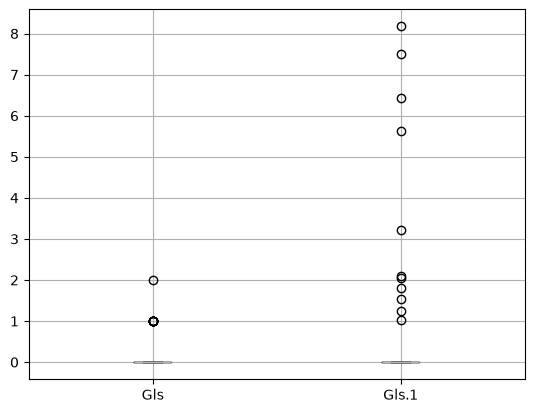

In [78]:
df_canteranos = df_nodup[df_nodup['Min'] < 90]
boxplot = df_canteranos.boxplot(column=['Gls', 'Gls.1'])
plt.show()

En la representación de arriba, vemos como un jugador que no jugó mucho tiene una media de más de 8 goles cada 90 minutos, es un atípico enorme. En general, es atípico que marquen goles.

Vamos a borrar las filas que tienen pos = GK y las que han jugado menos de 90 minutos:

In [79]:
df_filtrado = df_nodup[(df_nodup['Pos'] != 'GK') & (df_nodup['Min'] >= 90)]
print(f"Quedan {df_filtrado.shape[0]} jugadores después del filtrado.")

Quedan 2181 jugadores después del filtrado.


Otro dato que perdemos es el enlace que te conecta a los partidos que ha jugado en esa temporada el jugador. Si quisiésemos recuperar el enlace, en el caso de Brenden Aaronson, tendríamos que reconstruirlo usando el atributo de la última columna, la temporada que queremos mirar (en nuestro caso 2025-2026) y su nombre separado por guiones para poder ver todos los partidos que jugó durante la temporada. (https://fbref.com/en/players/5bc43860/matchlogs/2025-2026/summary/Brenden-Aaronson-Match-Logs)

Ahora que sabemos que estas columnas no nos sirven para modelar, podemos borrar las columnas _Matches_ y _-9999_.

**Vamos a borrar esas dos columnas:**

In [80]:
df_filtrado = df_filtrado.drop(columns=['-9999'])
df_filtrado.head()

,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,...,G+A.1,G-PK.1,G+A-PK,n_clubes,traspaso,liga_de Bundesliga,liga_eng Premier League,liga_es La Liga,liga_fr Ligue 1,liga_it Serie A
0,Brenden Aaronson,us USA,MFFW,Leeds United,eng Premier League,24.0,2000.0,37,30,2449,...,0.33,0.15,0.33,1,False,0.0,1.0,0.0,0.0,0.0
2,Zach Abbott,eng ENG,DF,Nottingham,eng Premier League,19.0,2006.0,3,2,164,...,0.00,0.00,0.00,1,False,0.0,1.0,0.0,0.0,0.0
3,Jones El-Abdellaoui,ma MAR,MFFW,Celta Vigo,es La Liga,19.0,2006.0,22,4,681,...,0.26,0.26,0.26,1,False,0.0,0.0,1.0,0.0,0.0
4,Ali Abdi,tn TUN,MFDF,Nice,fr Ligue 1,31.0,1993.0,22,13,1187,...,0.23,0.23,0.23,1,False,0.0,0.0,0.0,1.0,0.0
5,Salis Abdul Samed,gh GHA,MF,Nice,fr Ligue 1,25.0,2000.0,18,12,911,...,0.00,0.00,0.00,1,False,0.0,0.0,0.0,1.0,0.0


Más cosas que no queremos son el nombre, la nación y el equipo. El nombre no lo queremos porque identifica al jugador, y la nación y el equipo nos forzaría a añadir muchísimas variables dummy (~110 naciones y ~90 equipos distintos). No queremos sufrir de maldición de la dimensionalidad así que vamos a excluirlas también.

**Borremos otras tres columnas:**

In [81]:
df_filtrado = df_filtrado.drop(columns=['Player', 'Nation', 'Squad'])
df_filtrado.head()

,Pos,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,...,G+A.1,G-PK.1,G+A-PK,n_clubes,traspaso,liga_de Bundesliga,liga_eng Premier League,liga_es La Liga,liga_fr Ligue 1,liga_it Serie A
0,MFFW,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,...,0.33,0.15,0.33,1,False,0.0,1.0,0.0,0.0,0.0
2,DF,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,...,0.00,0.00,0.00,1,False,0.0,1.0,0.0,0.0,0.0
3,MFFW,es La Liga,19.0,2006.0,22,4,681,7.6,2,0,...,0.26,0.26,0.26,1,False,0.0,0.0,1.0,0.0,0.0
4,MFDF,fr Ligue 1,31.0,1993.0,22,13,1187,13.2,3,0,...,0.23,0.23,0.23,1,False,0.0,0.0,0.0,1.0,0.0
5,MF,fr Ligue 1,25.0,2000.0,18,12,911,10.1,0,0,...,0.00,0.00,0.00,1,False,0.0,0.0,0.0,1.0,0.0


In [82]:
df_filtrado["Pos"].unique()

<StringArray>
['MFFW', 'DF', 'MFDF', 'MF', 'FWMF', 'DFMF', 'FW']
Length: 7, dtype: str

Cambiemos el formato con el que guardamos la *Pos* y la *Comp*:

En el de *Pos* lo que haremos es convertirla en una binaria, queremos saber si el jugador juega de delantero (tiene FW o alguna combinación que lo incluya) o no. Arriba hemos visto que los que contienen *foward* son FW, MFFW, FWMF y DFFW, serán 1. El resto serán 0.

Hagamos las transformaciones:

In [83]:
df_filtrado['Rol_Ofensivo'] = df_filtrado['Pos'].str.contains('FW').astype(int)
display(df_filtrado[['Pos', 'Rol_Ofensivo']].value_counts()) # comprobando si estan bien asignados
# los tres delantero-defensas han sido excluidos por ser canteranos o por valores faltantes, una de dos
print(df_filtrado['Rol_Ofensivo'].value_counts()) # veamos cuantos tenemos de cada tipo

Pos   Rol_Ofensivo
MF    0               739
DF    0               608
FW    1               274
MFFW  1               207
DFMF  0               126
FWMF  1               114
MFDF  0               113
Name: count, dtype: int64

Rol_Ofensivo
0    1586
1     595
Name: count, dtype: int64


In [84]:
# ahora que hemos visto que esta bien, borramos la variable pos
df_filtrado = df_filtrado.drop(columns=['Pos'])

In [85]:
# df_filtrado = df_filtrado.drop(columns=['Born', '90s', 'G+A', 'G+A.1']) Provisional hasta acabar eda, que si no hay cosas que no se pueden explorar

Nuestra base de datos termina quedando así, después de todo esto:

In [86]:
df_filtrado.head()

,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,...,G-PK.1,G+A-PK,n_clubes,traspaso,liga_de Bundesliga,liga_eng Premier League,liga_es La Liga,liga_fr Ligue 1,liga_it Serie A,Rol_Ofensivo
0,eng Premier League,24.0,2000.0,37,30,2449,27.2,4,5,9,...,0.15,0.33,1,False,0.0,1.0,0.0,0.0,0.0,1
2,eng Premier League,19.0,2006.0,3,2,164,1.8,0,0,0,...,0.00,0.00,1,False,0.0,1.0,0.0,0.0,0.0,0
3,es La Liga,19.0,2006.0,22,4,681,7.6,2,0,2,...,0.26,0.26,1,False,0.0,0.0,1.0,0.0,0.0,1
4,fr Ligue 1,31.0,1993.0,22,13,1187,13.2,3,0,3,...,0.23,0.23,1,False,0.0,0.0,0.0,1.0,0.0,0
5,fr Ligue 1,25.0,2000.0,18,12,911,10.1,0,0,0,...,0.00,0.00,1,False,0.0,0.0,0.0,1.0,0.0,0


In [87]:
print(f"Disponemos de {df_filtrado.shape[0]} jugadores y {df_filtrado.shape[1]} atributos.")

Disponemos de 2181 jugadores y 28 atributos.


Hemos reducido bastantes dimensiones, teniendo en cuenta que luego vamos a quitar más.

## 1.5 EDA

Estructuramos el análisis exploratorio en cinco pasos sencillos, trabajando siempre sobre la partición de entrenamiento para evitar fuga de información:
1. **1.5.1 Partición Train / Test** y balance de la variable objetivo.
2. **1.5.2 Resumen general y función auxiliar** para inspeccionar cada variable y sus *outliers*.
3. **1.5.3 Análisis variable por variable** (viendo en código si los *outliers* son ruido o señal válida y qué aporta cada una al modelado).
4. **1.5.4 Correlaciones (Pearson y Spearman) e Información Mutua** con la variable objetivo.
5. **1.5.5 Limpieza final post-EDA** de las variables redundantes exactas en `X_train` y `X_test`.

### 1.5.1 Partición Train / Test y Balance de Clases

Separamos primero el conjunto de datos en **Train (80%)** y **Test (20%)** de forma estratificada sobre `Rol_Ofensivo`. El conjunto de `Test` se reserva intacto para la evaluación final y todo el EDA se realiza exclusivamente sobre `Train` (donde aplicaremos validación cruzada durante el modelado).

,n,Clase 0 (No Ofensivo),Clase 1 (Ofensivo),% Ofensivo,Ratio 0:1,Nulos
Total,2181,1586,595,27.28,2.67,0
Train (80%),1744,1268,476,27.29,2.66,0
Test (20%),437,318,119,27.23,2.67,0


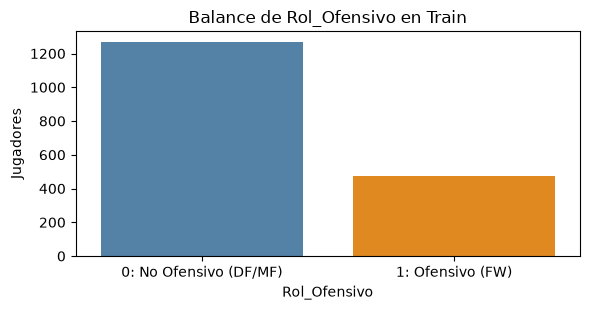

In [88]:
y = df_filtrado['Rol_Ofensivo'].astype(int)
X = df_filtrado.drop(columns=['Rol_Ofensivo']).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

train_df = X_train.copy()
train_df['Rol_Ofensivo'] = y_train

resumen_split = pd.DataFrame({
    'n': [len(df_filtrado), len(X_train), len(X_test)],
    'Clase 0 (No Ofensivo)': [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'Clase 1 (Ofensivo)': [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    '% Ofensivo': [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
    'Ratio 0:1': [(y == 0).sum() / (y == 1).sum(), (y_train == 0).sum() / (y_train == 1).sum(), (y_test == 0).sum() / (y_test == 1).sum()],
    'Nulos': [df_filtrado.isna().sum().sum(), X_train.isna().sum().sum(), X_test.isna().sum().sum()]
}, index=['Total', 'Train (80%)', 'Test (20%)']).round(2)
display(resumen_split)

fig, ax = plt.subplots(figsize=(6, 3.2))
sns.countplot(x=y_train, hue=y_train, palette=['steelblue', 'darkorange'], legend=False, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['0: No Ofensivo (DF/MF)', '1: Ofensivo (FW)'])
ax.set_title('Balance de Rol_Ofensivo en Train')
ax.set_ylabel('Jugadores')
plt.tight_layout()
plt.show()

La partición estratificada mantiene la misma proporción de clases en `Train` y `Test` sin valores nulos. Al existir desbalanceo hacia la clase `0` (No Ofensivo) (aunque sea ligero), un modelo que predijera siempre la clase mayoritaria acertaría la mayoría de los casos sin detectar delanteros; por ello en el modelado utilizaremos **Recall**, **F2-Score** y **ROC-AUC** además del Accuracy.

### 1.5.2 Resumen General y Función Auxiliar

Mostramos primero los estadísticos descriptivos de `X_train` y definimos una función sencilla (`analizar_variable`) para inspeccionar cada variable sin repetir código. Para no exagerar conclusiones a partir de diferencias pequeñas (que en una muestra de este tamaño o en subgrupos reducidos pueden deberse a simple variabilidad estadística), la función muestra:
1. Estadísticos por clase (`mean`, `std`, `median`, `IQR`) y su correlación lineal (`r_pb`) con `Rol_Ofensivo`, para comparar la diferencia entre clases frente a la dispersión real de los datos.
2. Resumen de *outliers* según el criterio IQR y el tamaño (`N`) de cada subgrupo.
3. Los 5 jugadores con valores más altos en `Train` y las gráficas de distribución y boxplot por clase, a partir de los cuales planteamos hipótesis sencillas para el modelado.

In [89]:
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

# Tabla descriptiva general sobre Train
resumen_general = X_train[num_cols].describe().T
resumen_general['skew'] = X_train[num_cols].skew()
resumen_general['% ceros'] = (X_train[num_cols] == 0).mean() * 100
display(resumen_general.round(2))

# Metadatos SOLO de Train para identificar a qué jugadores corresponden los outliers
info_train = df_nodup.loc[X_train.index, ['Player', 'Pos', 'Squad', 'Min']].copy()
info_train['Rol_Ofensivo'] = y_train


def analizar_variable(col, es_tasa=False):
    s = train_df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    ub = q3 + 1.5 * (q3 - q1)
    outliers = train_df[s > ub]
    r_pb, _ = pointbiserialr(y_train, s)

    # estadísticos por clase y correlación con el target
    por_clase = train_df.groupby('Rol_Ofensivo')[col].agg(
        ['count', 'mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)]
    ).rename(columns={'<lambda_0>': 'IQR'}).round(2)
    por_clase['corr_target'] = round(r_pb, 3)
    display(por_clase)

    # resumen de outliers iqr
    fila_out = {
        'Variable': col,
        'Umbral IQR': round(ub, 2),
        'N Outliers (>UB)': len(outliers),
        '% Muestra': round(len(outliers) / len(train_df) * 100, 1),
        '% Ofensivos en Outliers': round(outliers['Rol_Ofensivo'].mean() * 100, 1) if len(outliers) else np.nan,
        '% Ofensivos Base': round(y_train.mean() * 100, 1)
    }
    if es_tasa and len(outliers) > 0:
        pocos_min = outliers[outliers['Min'] < 270]
        muchos_min = outliers[outliers['Min'] >= 270]
        fila_out['N (Min<270)'] = len(pocos_min)
        fila_out['% Ofens (Min<270)'] = round(pocos_min['Rol_Ofensivo'].mean() * 100, 1) if len(pocos_min) else np.nan
        fila_out['N (Min>=270)'] = len(muchos_min)
        fila_out['% Ofens (Min>=270)'] = round(muchos_min['Rol_Ofensivo'].mean() * 100, 1) if len(muchos_min) else np.nan
    display(pd.DataFrame([fila_out]))

    # top 5 valores más altos en train
    display(info_train.assign(**{col: s}).nlargest(5, col)[['Player', 'Pos', 'Rol_Ofensivo', 'Squad', 'Min', col]])

    # gráficos
    es_discreta = s.nunique() <= 15
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    sns.histplot(
        data=train_df, x=col, hue='Rol_Ofensivo',
        discrete=es_discreta, kde=(not es_discreta),
        stat=('probability' if es_discreta else 'density'),
        common_norm=False, palette=['steelblue', 'darkorange'], ax=ax[0]
    )
    ax[0].set_title(f'Distribución de {col} por clase')

    sns.boxplot(
        data=train_df, x='Rol_Ofensivo', y=col, hue='Rol_Ofensivo',
        palette=['steelblue', 'darkorange'], legend=False, ax=ax[1]
    )
    ax[1].set_title(f'Boxplot de {col} por clase')
    plt.tight_layout()
    plt.show()

,count,mean,std,min,25%,50%,75%,max,skew,% ceros
Age,1744.0,25.12,4.36,15.0,22.00,25.00,28.00,41.00,0.40,0.00
Born,1744.0,1999.52,4.37,1983.0,1997.00,2000.00,2003.00,2009.00,-0.41,0.00
MP,1744.0,22.86,9.44,1.0,15.00,25.00,31.00,39.00,-0.43,0.00
Starts,1744.0,15.95,10.20,0.0,7.00,15.00,24.00,38.00,0.21,1.72
Min,1744.0,1427.58,857.71,90.0,677.75,1362.00,2099.50,3420.00,0.23,0.00
90s,1744.0,15.86,9.53,1.0,7.50,15.15,23.30,38.00,0.23,0.00
Gls,1744.0,2.13,3.18,0.0,0.00,1.00,3.00,36.00,2.92,37.21
Ast,1744.0,1.50,1.97,0.0,0.00,1.00,2.00,21.00,2.64,39.68
G+A,1744.0,3.63,4.36,0.0,1.00,2.00,5.00,41.00,2.31,22.08
G-PK,1744.0,1.93,2.76,0.0,0.00,1.00,3.00,26.00,2.55,37.96


### 1.5.3 Análisis Variable por Variable

Inspeccionamos cada variable de `X_train` individualmente. Las variables que son copias exactas (`Born`, `90s`, `G+A`, `G+A.1`, `n_clubes`) se comprueban en código junto a su variable principal para no duplicar gráficos y se eliminan al final del EDA.

#### 1.5.3.1 `Age` (Edad) *(y `Born`)*

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,25.20,4.35,25.0,6.0,-0.033
1,476,24.88,4.38,25.0,6.0,-0.033


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Age,37.0,12,0.7,50.0,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Age
582,Dante,DF,0,Nice,849,41.0
724,Edin Džeko,FW,1,Fiorentina,244,39.0
1591,Luka Modrić,MF,0,Milan,2811,39.0
1571,James Milner,MF,0,Brighton,784,39.0
66,Raúl Albiol,DF,0,Pisa,500,39.0


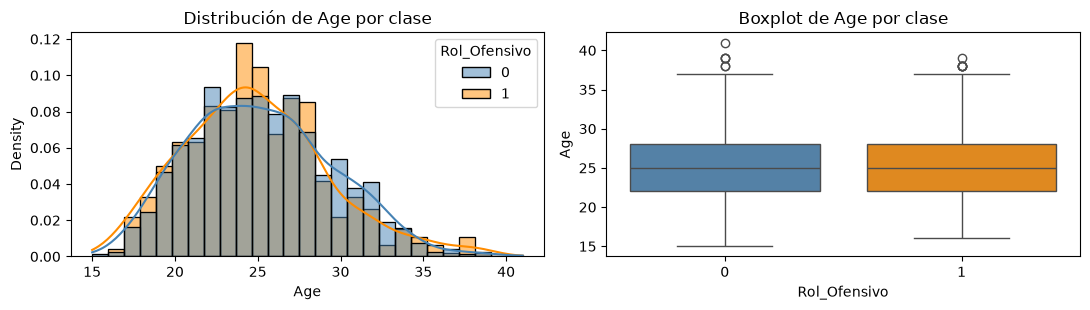

Correlación de Pearson entre Age y Born: -0.994


In [90]:
analizar_variable('Age')
print('Correlación de Pearson entre Age y Born:', round(X_train['Age'].corr(X_train['Born']), 4))

Vemos que **(`Age` y `Born`):** No son tan diferentes entre clases, viendo que están mayormente solapadas, por lo que a priori por sí misma no parece ser un predictor útil de si alguien ocupa un rol ofensivo en el campo, teniendo outliers que son plausibles por lo que no serán quitados (hay jugadores que llegan a jugar hasta 40 años, otra cosa es que alguno tuviera 80 años, o 12 años), teniendo además de aquellos que son menores de edad es posible que jueguen y su traspaso incluido, ya que contamos solo dentro de las ligas europeas, por ende dentro de la Unión Europea, donde si está permitido el traspaso de jugadores menores. Lo único a tener en cuenta es la redundancia Age y Born, siendo que una tiene que ser eliminado para evitar multicolinealidad perfecta

#### 1.5.3.2 `MP` (Partidos disputados)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,22.57,9.59,24.0,15.25,0.05
1,476,23.63,8.98,26.0,15.00,0.05


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,MP,55.0,0,0.0,NaN,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,MP
2556,Donyell Malen,FW,1,Roma,2123,39
1584,Tyrick Mitchell,MF,0,Crystal Palace,3251,38
330,Jarrod Bowen,MFFW,1,West Ham,3403,38
880,James Garner,MFDF,0,Everton,3413,38
1696,Victor Nelsson,DF,0,Hellas Verona,3315,38


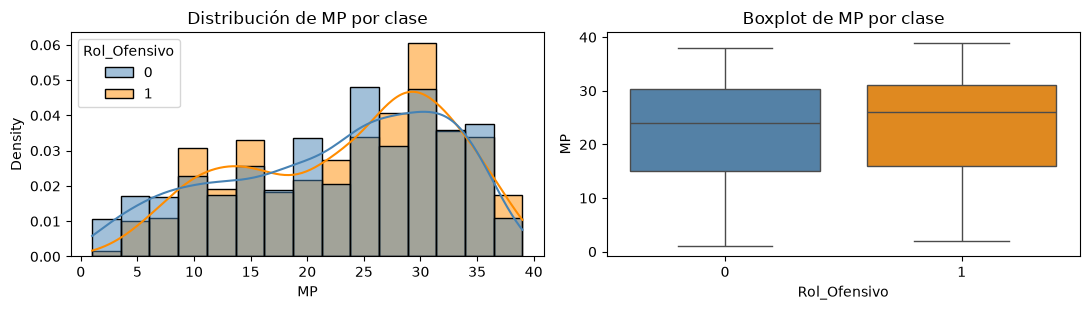

Jugadores con más de 38 partidos (por traspaso invernal entre calendarios):


,Player,Pos,Squad,Min,Rol_Ofensivo,MP,traspaso
2556,Donyell Malen,FW,Roma,2123,1,39,True


In [91]:
# 1.5.3.2 MP (Partidos disputados)
analizar_variable('MP')
print('Jugadores con más de 38 partidos (por traspaso invernal entre calendarios):')
display(info_train.assign(MP=X_train['MP'], traspaso=X_train['traspaso'])[X_train['MP'] > 38])

**(`MP`):** De forma similar a Age, vemos que por sí misma no parece a primera vista un predictor significativo de si el jugador desempeña un rol ofensivo

#### 1.5.3.3 `Starts` (Partidos como titular)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,16.64,10.41,16.0,17.0,-0.11
1,476,14.11,9.38,13.0,15.0,-0.11


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Starts,49.5,0,0.0,NaN,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Starts
330,Jarrod Bowen,MFFW,1,West Ham,3403,38
880,James Garner,MFDF,0,Everton,3413,38
2359,Adrien Truffert,DF,0,Bournemouth,3379,38
2394,Virgil van Dijk,DF,0,Liverpool,3420,38
1170,Pierre Kalulu,DFMF,0,Juventus,3281,37


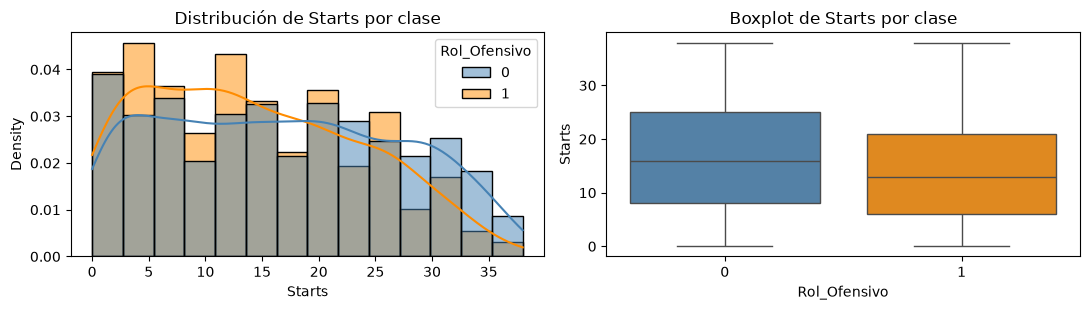

Separación del cociente Starts / MP (tasa de titularidad):


,mean,std,median,corr_target
Rol_Ofensivo,,,,
0,0.69,0.26,0.75,-0.235
1,0.54,0.26,0.57,-0.235


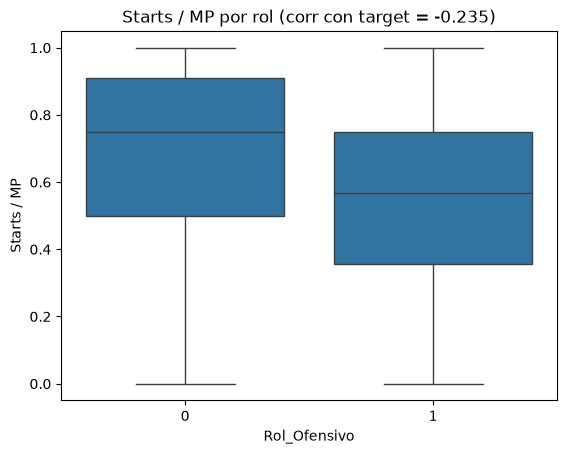

In [92]:
analizar_variable('Starts')

ratio_titular = X_train['Starts'] / X_train['MP']
r_ratio, _ = pointbiserialr(y_train, ratio_titular)
resumen_ratio = train_df.assign(Starts_MP=ratio_titular).groupby('Rol_Ofensivo')['Starts_MP'].agg(['mean', 'std', 'median']).round(2)
resumen_ratio['corr_target'] = round(r_ratio, 3)
print('Separación del cociente Starts / MP (tasa de titularidad):')
display(resumen_ratio)

sns.boxplot(x=train_df['Rol_Ofensivo'], y=ratio_titular)
plt.title(f'Starts / MP por rol (corr con target = {r_ratio:.3f})')
plt.ylabel('Starts / MP')
plt.show()

**(`Starts`):** Igual que las anteriores, distribuciones muy similares entre clases, por lo que no parece a priori un predictor por sí mismo muy útil.
Donde si apreciamos mayor diferencia es en la tasa de titularidad, pero esta de nuevo, sigue sin ser algo que a priori parezca que vaya a ayudar, vemos incluso ambos bigotes van de 0 a 1.

#### 1.5.3.4 `Min` (Minutos totales) *(y `90s`)*

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,1486.89,885.64,1452.0,1487.25,-0.113
1,476,1269.58,756.93,1206.0,1253.25,-0.113


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Min,4232.12,0,0.0,NaN,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Min
2394,Virgil van Dijk,DF,0,Liverpool,3420,3420
880,James Garner,MFDF,0,Everton,3413,3413
330,Jarrod Bowen,MFFW,1,West Ham,3403,3403
2359,Adrien Truffert,DF,0,Bournemouth,3379,3379
103,Elliot Anderson,MF,0,Nottingham,3331,3331


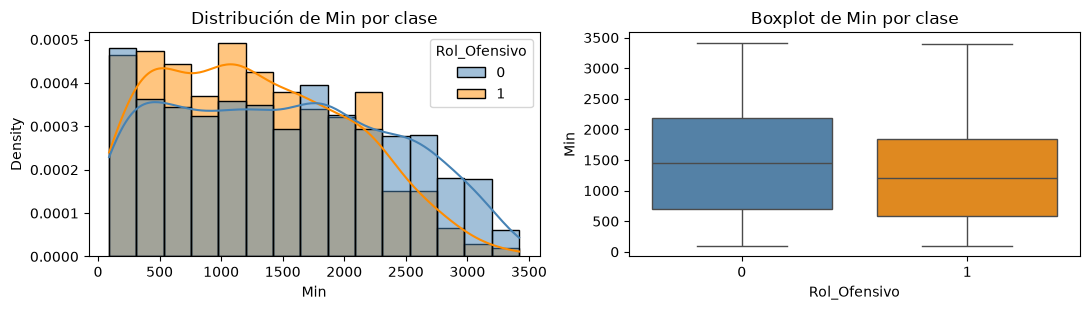

Correlación de Pearson entre Min y 90s: 1.0
Separación del cociente Min / MP (minutos por partido jugado):


,mean,std,median,corr_target
Rol_Ofensivo,,,,
0,61.71,19.61,65.41,-0.267
1,49.81,17.80,50.32,-0.267


,Umbral,N jugadores,% Train
0,< 3 partidos (270 min),154,8.8
1,< 5 partidos (450 min),276,15.8
2,< 10 partidos (900 min),560,32.1
3,< 15 partidos (1350 min),867,49.7


In [93]:
analizar_variable('Min')

print('Correlación de Pearson entre Min y 90s:', round(X_train['Min'].corr(X_train['90s']), 4))

min_por_partido = X_train['Min'] / X_train['MP']
r_min_mp, _ = pointbiserialr(y_train, min_por_partido)
resumen_min_mp = train_df.assign(Min_MP=min_por_partido).groupby('Rol_Ofensivo')['Min_MP'].agg(['mean', 'std', 'median']).round(2)
resumen_min_mp['corr_target'] = round(r_min_mp, 3)
print('Separación del cociente Min / MP (minutos por partido jugado):')
display(resumen_min_mp)

tramos_min = pd.DataFrame([
    {'Umbral': f'< {p} partidos ({p*90} min)', 'N jugadores': int((X_train['Min'] < p*90).sum()),
     '% Train': round((X_train['Min'] < p*90).mean() * 100, 1)}
    for p in [3, 5, 10, 15]
])
display(tramos_min)

**(`Min` y `90s`):** Mismo caso que las variables predictoras anteriores, no parece un predictor fuerte con este primer vistazo, de nuevo en el boxplot se aprecia como los bigotes de ambas clases van de 0 a aproximadamente 3500 habiendo mucho solapamiento. Lo único a sacar de aquí es que solo nos quedaremos con una para evitar multicolinealidad fuerte que puede volver inestables los modelos lineales.

In [94]:
print(f'El RMSE de aproximar MIN por 90s es {np.sqrt(np.mean(((train_df["90s"] * 90 - train_df["Min"])**2))):.4f} minutos')

El RMSE de aproximar MIN por 90s es 2.6546 minutos


#### 1.5.3.5 `Gls` (Goles totales) *(y `G+A`)*

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,1.32,2.02,1.0,2.0,0.42
1,476,4.31,4.43,3.0,5.0,0.42


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Gls,7.5,120,6.9,78.3,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Gls
1183,Harry Kane,FWMF,1,Bayern Munich,2377,36
1653,Vedat Muriqi,FW,1,Mallorca,3128,23
2308,Igor Thiago,FW,1,Brentford,3282,22
2619,Esteban Lepaul,FW,1,Rennes,2685,21
2376,Deniz Undav,FWMF,1,Stuttgart,2241,19


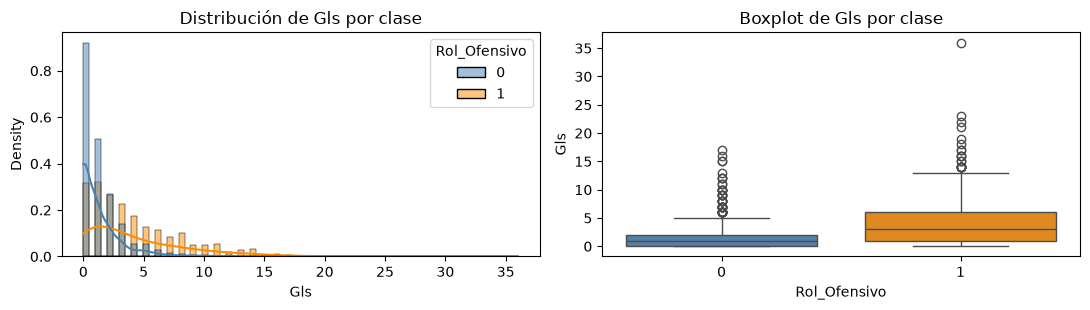

Diferencia máxima |G+A - (Gls + Ast)|: 0
Diferencia máxima |Gls - (G-PK + PK)|: 0


In [95]:
analizar_variable('Gls')
print('Diferencia máxima |G+A - (Gls + Ast)|:', (X_train['G+A'] - (X_train['Gls'] + X_train['Ast'])).abs().max())
print('Diferencia máxima |Gls - (G-PK + PK)|:', (X_train['Gls'] - (X_train['G-PK'] + X_train['PK'])).abs().max())

**(`Gls` y `G+A`):** Aquí si podemos observar una mayor diferencia entre distribuciones, siendo que la de la clase ofensiva está menos concentrada en cero con una cola mas pesada, lo cual si será de utilidad en los modelos. Lo único a tratar es la multicolinealidad de nuevo, siendo Gls = Goles sin contar penaltis + Goles de penalti y G+A = Goles + Asistencias. Por lo que con tantas colinealidades perfectas que habrá podemos intuir ya que el primer modelo logístico será un desastre que sufrirá de colinealidades sin saber a que variables atribuir realmente la discriminación

#### 1.5.3.6 `G-PK` (Goles sin penalti)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,1.24,1.85,1.0,2.0,0.414
1,476,3.80,3.75,3.0,5.0,0.414


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,G-PK,7.5,93,5.3,78.5,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,G-PK
1183,Harry Kane,FWMF,1,Bayern Munich,2377,26
2376,Deniz Undav,FWMF,1,Stuttgart,2241,19
1653,Vedat Muriqi,FW,1,Mallorca,3128,18
2619,Esteban Lepaul,FW,1,Rennes,2685,18
1485,Lautaro Martínez,FW,1,Inter,2159,17


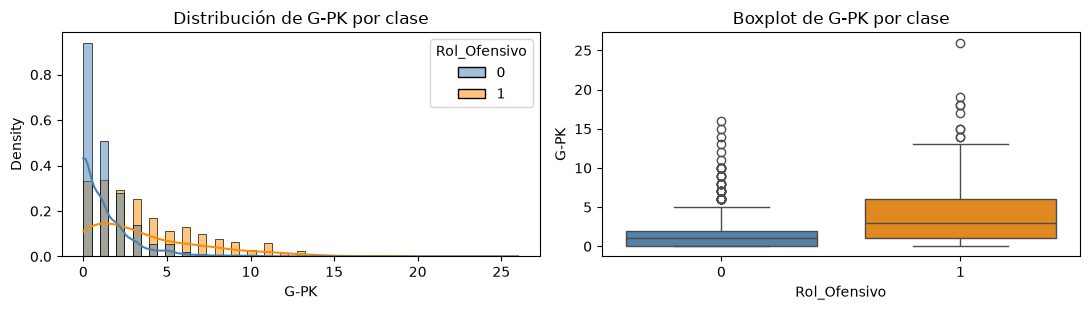

Correlación de Pearson entre Gls y G-PK: 0.9744


In [96]:
analizar_variable('G-PK')
print('Correlación de Pearson entre Gls y G-PK:', round(X_train['Gls'].corr(X_train['G-PK']), 4))

**(`G-PK`):** Muy parecida a la variable Gls, lógico si nos acordamos de que esta última es la suma de G-Pk + Pk. Por lo que las conclusiones acerca de esta ya han sido tomadas en el análisis anterior, quitar alguna para evitar multicolinealidad perfecta

#### 1.5.3.7 `PK` y `PKatt` (Penaltis convertidos e intentados)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.08,0.50,0.0,0.0,0.243
1,476,0.51,1.22,0.0,0.0,0.243


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,PK,0.0,161,9.2,69.6,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,PK
1183,Harry Kane,FWMF,1,Bayern Munich,2377,10
2308,Igor Thiago,FW,1,Brentford,3282,8
95,Nadiem Amiri,MF,0,Mainz 05,2083,8
1806,Mikel Oyarzabal,FW,1,Real Sociedad,2710,7
607,Romain Del Castillo,MFFW,1,Brest,2625,6


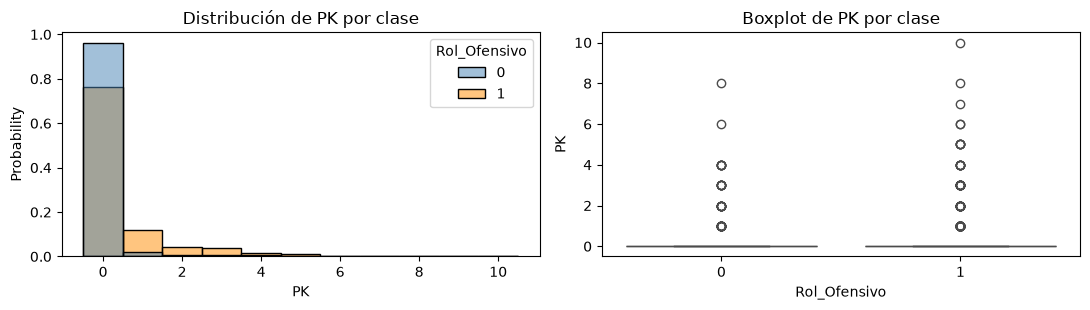

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.10,0.57,0.0,0.0,0.267
1,476,0.66,1.43,0.0,1.0,0.267


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,PKatt,0.0,199,11.4,68.3,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,PKatt
1183,Harry Kane,FWMF,1,Bayern Munich,2377,11
2308,Igor Thiago,FW,1,Brentford,3282,9
607,Romain Del Castillo,MFFW,1,Brest,2625,8
356,Ante Budimir,FW,1,Osasuna,2938,8
95,Nadiem Amiri,MF,0,Mainz 05,2083,8


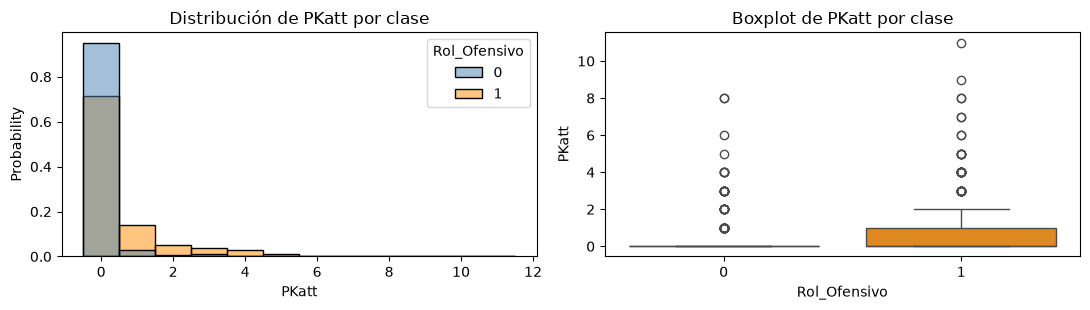

Correlación de Pearson entre PK y PKatt: 0.968


In [97]:
analizar_variable('PK')
analizar_variable('PKatt')
print('Correlación de Pearson entre PK y PKatt:', round(X_train['PK'].corr(X_train['PKatt']), 4))

**(`PK` y `PKatt`):** De forma similar a las anteriores las vemos concentradas en 0, lógico ya que un penalti no suele ser un evento tan común en un partido, donde vemos mayor capacidad discriminativa es en PKatt, donde vemos la mayoría de quien lanza penaltis son jugadores ofensivos (a excepción de algunos casos particulares, por ejemplo Sergio Ramos era defensa y chutaba muchos penaltis). Los posibles outliers marcados por el boxplot no son outliers peligrosos, sino en este caso una señal predictora muy util, dado que en este caso como hemos dicho no es lo habitual chutar penaltis y menos aún como observamos meterlos

#### 1.5.3.8 `Ast` (Asistencias totales)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,1.37,1.94,1.0,2.0,0.109
1,476,1.85,1.99,1.0,3.0,0.109


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,Ast,5.0,72,4.1,44.4,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Ast
796,Bruno Fernandes,MF,0,Manchester Utd,3063,21
1767,Michael Olise,MF,0,Bayern Munich,2316,19
665,Federico Dimarco,MF,0,Inter,2698,16
2049,Julian Ryerson,MF,0,Dortmund,2266,15
483,Rayan Cherki,MF,0,Manchester City,1786,12


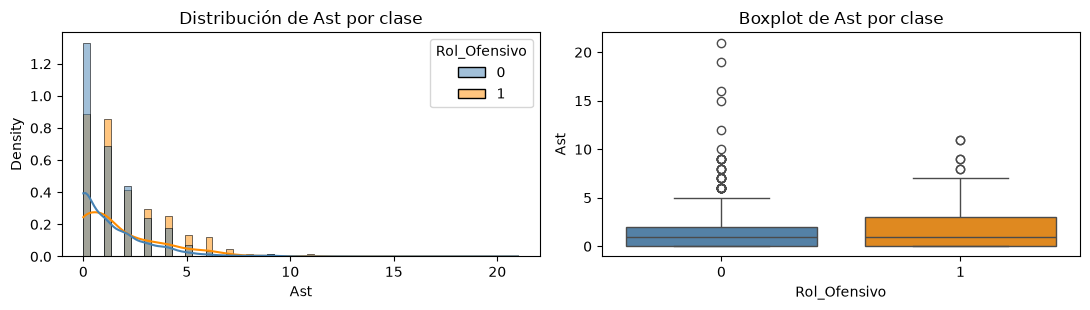

In [98]:
analizar_variable('Ast')

**(`Ast`):** Podemos observar como hay pequeñas diferencias pero sutiles, siendo que no parece a priori una variable útil por sí misma.

#### 1.5.3.9 `CrdY` (Tarjetas amarillas)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,3.32,2.68,3.0,4.0,-0.186
1,476,2.25,1.99,2.0,2.0,-0.186


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,CrdY,8.5,68,3.9,5.9,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,CrdY
437,Carmona,DFMF,0,Sevilla,2565,13
880,James Garner,MFDF,0,Everton,3413,12
1386,Pol Lozano,MF,0,Espanyol,2157,12
1910,Marin Pongračić,DF,0,Fiorentina,2918,12
37,Lucien Agoume,MF,0,Sevilla,2686,12


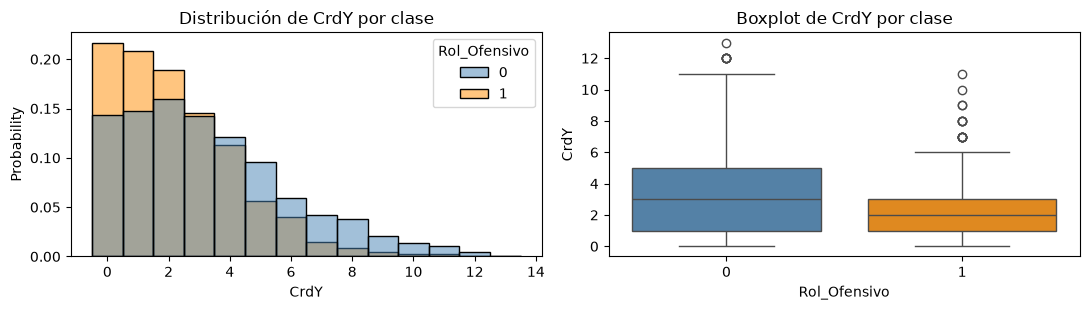

In [99]:
# 1.5.3.9 CrdY (Tarjetas amarillas)
analizar_variable('CrdY')

**(`CrdY`):** Observamos la principal diferencia (sútil) de que los jugadores ofensivos reciben menos tarjetas amarillas, tiene sentido ya que podemos pensar quien las comete es por una labor defensiva, no siendo ese el rol principal de los jugadores ofensivos

#### 1.5.3.10 `CrdR` (Tarjetas rojas)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.17,0.41,0.0,0.0,-0.072
1,476,0.11,0.34,0.0,0.0,-0.072


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base
0,CrdR,0.0,252,14.4,19.4,27.3


,Player,Pos,Rol_Ofensivo,Squad,Min,CrdR
2431,Federico Viñas,FWMF,1,Oviedo,2439,3
2464,Wesley,MF,0,Roma,2448,2
2020,Cristian Romero,DF,0,Tottenham,1868,2
2635,Endrick,FWMF,1,Lyon,1227,2
1544,Nobel Mendy,DF,0,Rayo Vallecano,1797,2


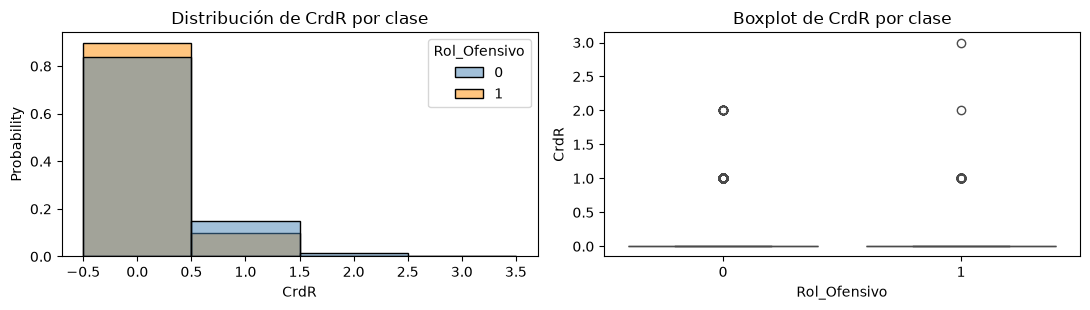

In [100]:
# 1.5.3.10 CrdR (Tarjetas rojas)
analizar_variable('CrdR')

**(`CrdR`):** Evento que como vemos es muy poco frecuente por lo que disponemos de muy poca información de el y como se aprecia las distribuciones están muy solapadas, por lo que no parece un predictor siquiera útil en lo más mínimo a priori

#### 1.5.3.11 `Gls.1` (Goles por 90 min) *(y `G+A.1`)*

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.08,0.12,0.04,0.11,0.499
1,476,0.28,0.22,0.24,0.27,0.499


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,N (Min<270),% Ofens (Min<270),N (Min>=270),% Ofens (Min>=270)
0,Gls.1,0.5,97,5.6,76.3,27.3,18,44.4,79,83.5


,Player,Pos,Rol_Ofensivo,Squad,Min,Gls.1
1183,Harry Kane,FWMF,1,Bayern Munich,2377,1.36
2247,Cristhian Stuani,FW,1,Girona,412,1.09
1083,Hamza Igamane,FW,1,Lille,432,1.04
2237,Orri Steinn Óskarsson,FW,1,Real Sociedad,835,0.97
1244,Adam Kölle,DF,0,Heidenheim,93,0.97


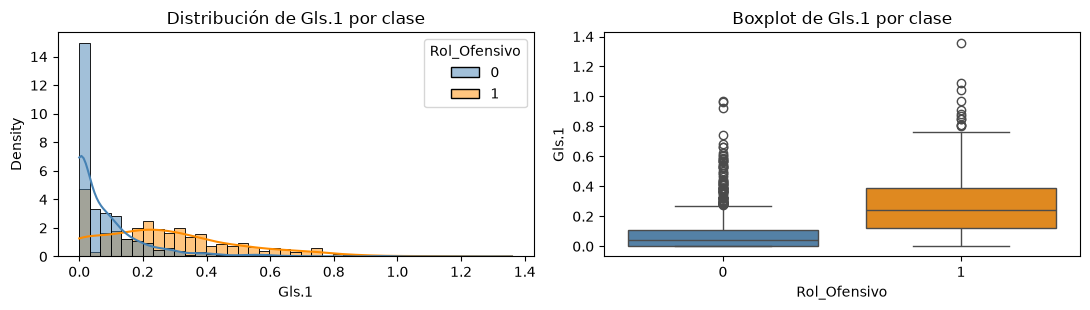

Diferencia máxima |G+A.1 - (Gls.1 + Ast.1)|: 0.01


In [101]:
analizar_variable('Gls.1', es_tasa=True)
print('Diferencia máxima |G+A.1 - (Gls.1 + Ast.1)|:', round((X_train['G+A.1'] - (X_train['Gls.1'] + X_train['Ast.1'])).abs().max(), 4))

**(`Gls.1` y `G+A.1`):** Aquí ya se aprecia una clara diferencia, dado que la mayoría para perfiles no ofensivos está concentrada en 0, mientras que para perfiles ofensivos tiene mayor peso irregular en la cola. El riesgo de este tipo de variables es que al ser una tasa por 90 minutos, alguien que haya jugado poco tiempo pero marque (por ejemplo le sacan los ultimos 10 minutos solo y marca gol) va a tener una tasa inflada no porque marque mucho sino por jugar poco. Incluso en el top 5 podemos ver como se cuela un defensa

#### 1.5.3.12 `G-PK.1` (Goles sin penalti por 90 min)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.07,0.12,0.03,0.10,0.481
1,476,0.25,0.20,0.22,0.26,0.481


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,N (Min<270),% Ofens (Min<270),N (Min>=270),% Ofens (Min>=270)
0,G-PK.1,0.45,103,5.9,75.7,27.3,20,40.0,83,84.3


,Player,Pos,Rol_Ofensivo,Squad,Min,G-PK.1
1083,Hamza Igamane,FW,1,Lille,432,1.04
1183,Harry Kane,FWMF,1,Bayern Munich,2377,0.98
2237,Orri Steinn Óskarsson,FW,1,Real Sociedad,835,0.97
1244,Adam Kölle,DF,0,Heidenheim,93,0.97
1961,Harrison Reed,MF,0,Fulham,94,0.96


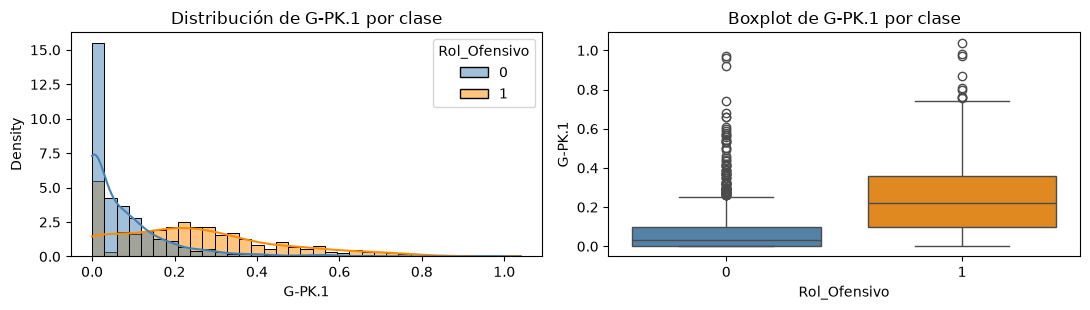

Correlación de Pearson entre Gls.1 y G-PK.1: 0.9684


In [102]:
# 1.5.3.12 G-PK.1 (Goles sin penalti por 90 min)
analizar_variable('G-PK.1', es_tasa=True)
print('Correlación de Pearson entre Gls.1 y G-PK.1:', round(X_train['Gls.1'].corr(X_train['G-PK.1']), 4))

**Interpretación (`G-PK.1`):** Ocurre lo mismo que en la variable anterior

#### 1.5.3.13 `Ast.1` (Asistencias por 90 min)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.08,0.12,0.05,0.12,0.15
1,476,0.12,0.12,0.10,0.19,0.15


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,N (Min<270),% Ofens (Min<270),N (Min>=270),% Ofens (Min>=270)
0,Ast.1,0.36,65,3.7,32.3,27.3,19,10.5,46,41.3


,Player,Pos,Rol_Ofensivo,Squad,Min,Ast.1
1778,Frank Onyeka,MF,0,Brentford,92,0.98
865,Ben Gannon-Doak,MF,0,Bournemouth,113,0.80
1590,Rui Modesto,MF,0,Udinese,119,0.76
237,Ismael Bekhoucha,DF,0,Getafe,122,0.74
1767,Michael Olise,MF,0,Bayern Munich,2316,0.74


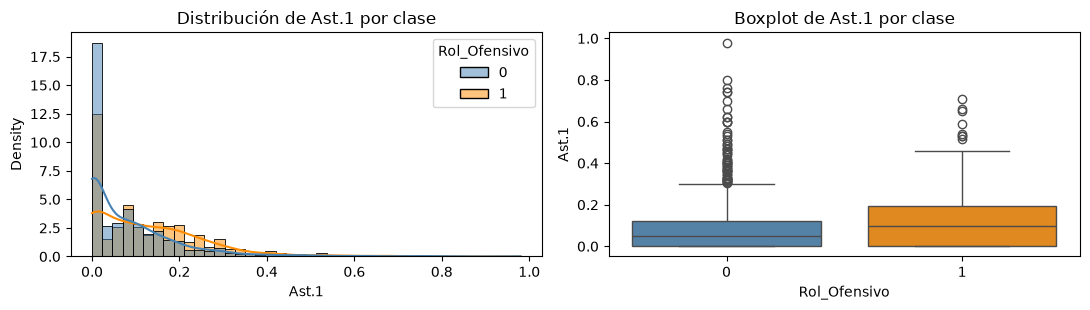

In [103]:
# 1.5.3.13 Ast.1 (Asistencias por 90 min)
analizar_variable('Ast.1', es_tasa=True)

**Interpretación (`Ast.1`):** Mismo problema que en las anteriores, aunque aquí no se aprecia tanta capacidad de discriminación por sí sola, y sirve para ilustrar que aquellos jugadores con mayor tasa tienen apenas minutos jugados en toda la temporada, lo que infla la métrica de manera engañosa

#### 1.5.3.14 `G+A-PK` (Goles sin penalti + Asistencias por 90 min)

,count,mean,std,median,IQR,corr_target
Rol_Ofensivo,,,,,,
0,1268,0.16,0.18,0.11,0.23,0.439
1,476,0.38,0.24,0.35,0.28,0.439


,Variable,Umbral IQR,N Outliers (>UB),% Muestra,% Ofensivos en Outliers,% Ofensivos Base,N (Min<270),% Ofens (Min<270),N (Min>=270),% Ofens (Min>=270)
0,G+A-PK,0.77,51,2.9,66.7,27.3,9,22.2,42,76.2


,Player,Pos,Rol_Ofensivo,Squad,Min,G+A-PK
2064,Allan Saint-Maximin,MF,0,Lens,410,1.32
1767,Michael Olise,MF,0,Bayern Munich,2316,1.32
2367,Stefanos Tzimas,FW,1,Brighton,139,1.29
615,Ousmane Dembélé,FW,1,Paris SG,1063,1.27
1083,Hamza Igamane,FW,1,Lille,432,1.25


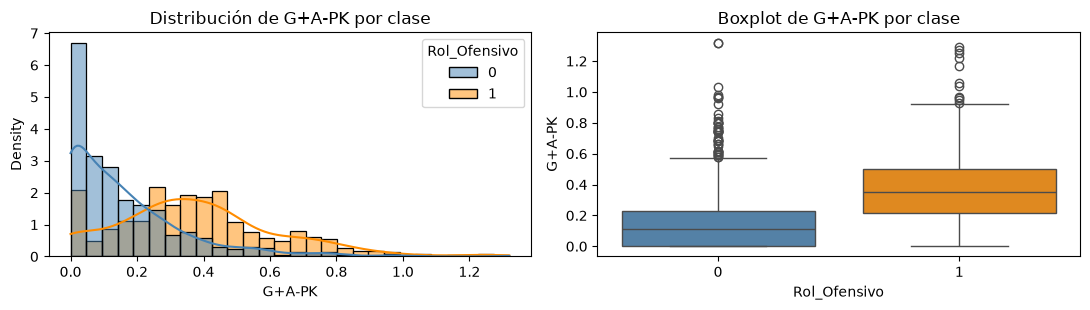

Diferencia máxima |G+A-PK - (G-PK.1 + Ast.1)|: 0.01


In [104]:
analizar_variable('G+A-PK', es_tasa=True)
print('Diferencia máxima |G+A-PK - (G-PK.1 + Ast.1)|:', round((X_train['G+A-PK'] - (X_train['G-PK.1'] + X_train['Ast.1'])).abs().max(), 4))

**Interpretación (`G+A-PK`):** Al ser la suma de G-PK.1 + Ast.1, hereda la misma distorsión en jugadores con pocos minutos (además de ser combinación lineal de ambas).

#### 1.5.3.15 `Comp` y `traspaso` *(y `n_clubes`)*

¿Son n_clubes y traspaso 100% equivalentes en Train?: True

--- Liga (Comp) ---


Rol_Ofensivo,0,1,N,% Ofensivo,chi2,p_valor
Liga,,,,,,
de Bundesliga,224,90,314,28.66,4.28,0.3698
eng Premier League,258,82,340,24.12,4.28,0.3698
es La Liga,265,105,370,28.38,4.28,0.3698
fr Ligue 1,234,101,335,30.15,4.28,0.3698
it Serie A,287,98,385,25.45,4.28,0.3698



--- Traspaso invernal ---


Rol_Ofensivo,0,1,N,% Ofensivo,chi2,p_valor
traspaso,,,,,,
False,1197,431,1628,26.47,7.67,0.0056
True,71,45,116,38.79,7.67,0.0056


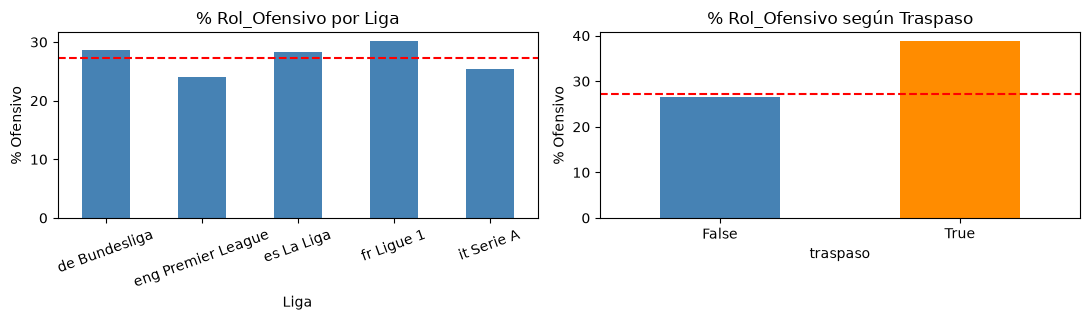

In [105]:
print('¿Son n_clubes y traspaso 100% equivalentes en Train?:', (X_train['n_clubes'] == (X_train['traspaso'].astype(int) + 1)).all())

liga_train = X_train['Comp'].rename('Liga')
for nombre, serie in [('Liga (Comp)', liga_train), ('Traspaso invernal', X_train['traspaso'])]:
    ct = pd.crosstab(serie, y_train)
    chi2, p_val, _, _ = chi2_contingency(ct)
    ct['N'] = ct.sum(axis=1)
    ct['% Ofensivo'] = (ct[1] / ct['N'] * 100).round(2)
    ct['chi2'] = round(chi2, 2)
    ct['p_valor'] = round(p_val, 4)
    print(f'\n--- {nombre} ---')
    display(ct)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
(pd.crosstab(liga_train, y_train, normalize='index')[1] * 100).plot(kind='bar', color='steelblue', ax=ax[0])
ax[0].axhline(y_train.mean() * 100, color='red', linestyle='--')
ax[0].set_title('% Rol_Ofensivo por Liga')
ax[0].set_ylabel('% Ofensivo')
ax[0].tick_params(axis='x', rotation=20)

(pd.crosstab(X_train['traspaso'], y_train, normalize='index')[1] * 100).plot(kind='bar', color=['steelblue', 'darkorange'], ax=ax[1])
ax[1].axhline(y_train.mean() * 100, color='red', linestyle='--')
ax[1].set_title('% Rol_Ofensivo según Traspaso')
ax[1].set_ylabel('% Ofensivo')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**(`Comp`, `traspaso` y `n_clubes`):**
* En **Comp (Liga)** las pequeñas diferencias entre competiciones no son significativas y entran dentro de la variabilidad normal entre muestras.
* En **traspaso**, vemos el porcentaje de jugadores con roles ofensivos es mayor, a priori parece será útil, aunque hay que tener en cuenta es un grupo de tamaño reducido, por lo que puede presentar una alta variabilidad

### 1.5.4 Clustering de Correlaciones (Dendrograma) e Información Mutua

En lugar de inspeccionar únicamente matrices de números, aplicamos **clustering jerárquico aglomerativo** sobre la distancia de correlación $d_{ij} = 1 - |r_{ij}|$ en `X_train` (tanto con **Pearson** como con **Spearman**) para agrupar automáticamente las variables colineales mediante un **dendrograma**. A continuación comparamos la correlación lineal frente a la **Información Mutua** con `Rol_Ofensivo`.

In [106]:
X_train.columns

Index(['Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast',
       'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'Gls.1', 'Ast.1', 'G+A.1',
       'G-PK.1', 'G+A-PK', 'n_clubes', 'traspaso', 'liga_de Bundesliga',
       'liga_eng Premier League', 'liga_es La Liga', 'liga_fr Ligue 1',
       'liga_it Serie A'],
      dtype='str')

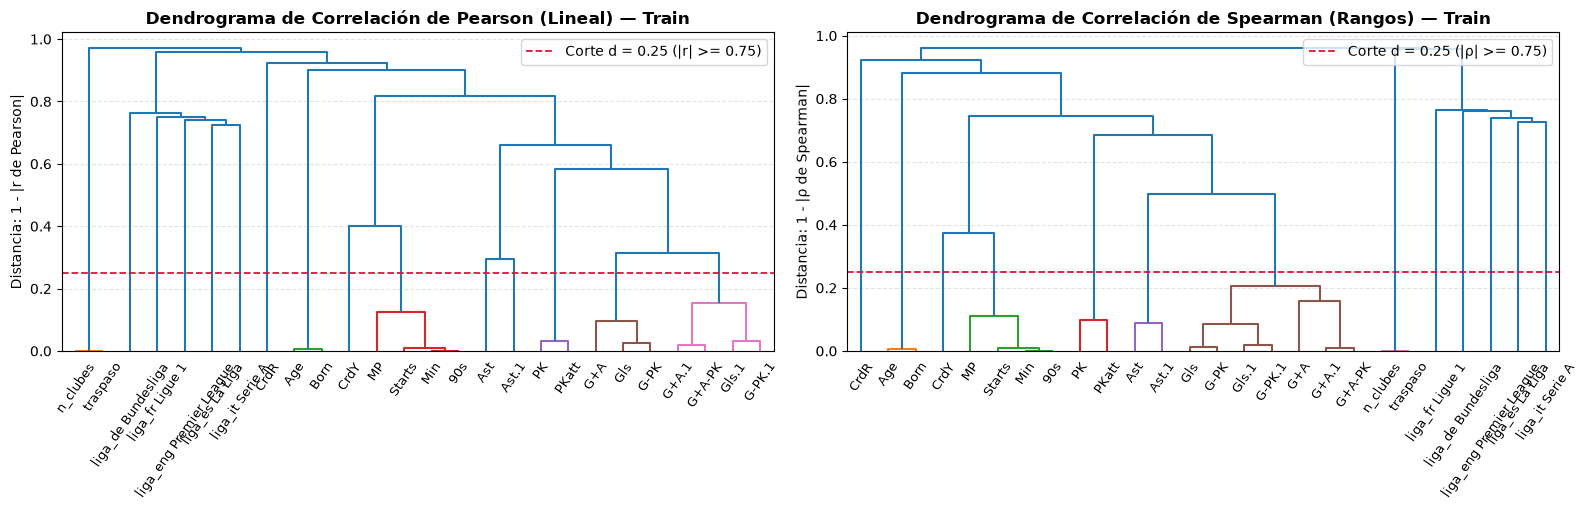


--- Clústeres por Pearson (Lineal, |r| >= 0.75) ---


,N_Variables,Variables_Agrupadas
0,4,"MP, Starts, Min, 90s"
1,4,"Gls.1, G+A.1, G-PK.1, G+A-PK"
2,3,"Gls, G+A, G-PK"
3,2,"PK, PKatt"
4,2,"n_clubes, traspaso"
5,2,"Age, Born"



--- Clústeres por Spearman (Monótona, |ρ| >= 0.75) ---


,N_Variables,Variables_Agrupadas
0,7,"Gls, G+A, G-PK, Gls.1, G+A.1, G-PK.1, G+A-PK"
1,4,"MP, Starts, Min, 90s"
2,2,"Age, Born"
3,2,"Ast, Ast.1"
4,2,"PK, PKatt"
5,2,"n_clubes, traspaso"


In [107]:
X_train_num = X_train.drop(columns='Comp').copy()
for c in X_train_num.columns:
    if not pd.api.types.is_numeric_dtype(X_train_num[c]):
        X_train_num[c] = X_train_num[c].astype(float)
    elif X_train_num[c].dtype == bool:
        X_train_num[c] = X_train_num[c].astype(int)

corr_pearson = X_train_num.corr(method='pearson').fillna(0)
corr_spearman = X_train_num.corr(method='spearman').fillna(0)

# d(i, j) = 1 - |r_ij|
dist_p = 1 - np.abs(corr_pearson.values)
dist_s = 1 - np.abs(corr_spearman.values)
dist_p = (dist_p + dist_p.T) / 2
dist_s = (dist_s + dist_s.T) / 2
np.fill_diagonal(dist_p, 0)
np.fill_diagonal(dist_s, 0)

Z_pearson = linkage(squareform(np.clip(dist_p, 0, None), checks=False), method='average')
Z_spearman = linkage(squareform(np.clip(dist_s, 0, None), checks=False), method='average')
umbral_dist = 0.25  # equivale a correlación media |r| >= 0.75 dentro del clúster

# dendogramas
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

dendrogram(Z_pearson, labels=X_train_num.columns.tolist(), leaf_rotation=55, leaf_font_size=9,
           color_threshold=umbral_dist, ax=axes[0])
axes[0].axhline(umbral_dist, color='crimson', linestyle='--', linewidth=1.3,
                label=f'Corte d = {umbral_dist} (|r| >= {1-umbral_dist:.2f})')
axes[0].set_ylabel('Distancia: 1 - |r de Pearson|')
axes[0].set_title('Dendrograma de Correlación de Pearson (Lineal) — Train', fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.35)

dendrogram(Z_spearman, labels=X_train_num.columns.tolist(), leaf_rotation=55, leaf_font_size=9,
           color_threshold=umbral_dist, ax=axes[1])
axes[1].axhline(umbral_dist, color='crimson', linestyle='--', linewidth=1.3,
                label=f'Corte d = {umbral_dist} (|ρ| >= {1-umbral_dist:.2f})')
axes[1].set_ylabel('Distancia: 1 - |ρ de Spearman|')
axes[1].set_title('Dendrograma de Correlación de Spearman (Rangos) — Train', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

# clústeres formados en Pearson y en Spearman al cortar en d = 0.25 (|r| >= 0.75)
cl_p = fcluster(Z_pearson, t=umbral_dist, criterion='distance')
cl_s = fcluster(Z_spearman, t=umbral_dist, criterion='distance')

for nombre, cl in [('Clústeres por Pearson (Lineal, |r| >= 0.75)', cl_p),
                   ('Clústeres por Spearman (Monótona, |ρ| >= 0.75)', cl_s)]:
    df_cl = pd.DataFrame({'Variable': X_train_num.columns, 'Cluster': cl})
    resumen_cl = (
        df_cl.groupby('Cluster')['Variable']
        .agg(N_Variables='count', Variables_Agrupadas=lambda s: ', '.join(s))
        .sort_values('N_Variables', ascending=False)
        .reset_index(drop=True)
    )
    print(f'\n--- {nombre} ---')
    display(resumen_cl[resumen_cl['N_Variables'] > 1])

El dendrograma de **Pearson** agrupa a distancia prácticamente cero las redundancias estructurales (`Min`–`90s`, `n_clubes`–`traspaso`, `Age`–`Born`) y separa cuatro bloques colineales: **tasas por 90 min** (`Gls.1, G+A.1, G-PK.1, G+A-PK`), **tiempo de participación** (`MP, Starts, Min, 90s`), **goles absolutos** (`Gls, G+A, G-PK`) y **penaltis** (`PK, PKatt`). En el dendrograma de **Spearman**, además, el clúster de tasas por 90 minutos se fusiona directamente con el de goles absolutos (y `Ast.1` se une con `Ast`), confirmando que las variables por 90 minutos contienen esencialmente la misma información ordenada que los conteos brutos pero distorsionada por el cociente en jugadores con pocos minutos. Por ello, en `1.5.5` descartaremos el clúster de tasas por 90 min junto a las redundancias estructurales y conservaremos los bloques de conteos y participación para la Sección II.

,Información Mutua (MI),MI (std),Corr. Biserial (r),Corr. Spearman (ρ)
Variable,,,,
Gls.1,0.1425,0.0077,0.4986,0.4713
G-PK.1,0.1373,0.0063,0.4811,0.4592
G+A.1,0.1347,0.0083,0.4592,0.4501
G+A-PK,0.1197,0.0076,0.4392,0.4367
Gls,0.0890,0.0073,0.4197,0.4046
G-PK,0.0872,0.0077,0.4135,0.3937
G+A,0.0697,0.0097,0.3553,0.3426
PKatt,0.0447,0.0098,0.2667,0.3313
PK,0.0381,0.0103,0.2426,0.3022


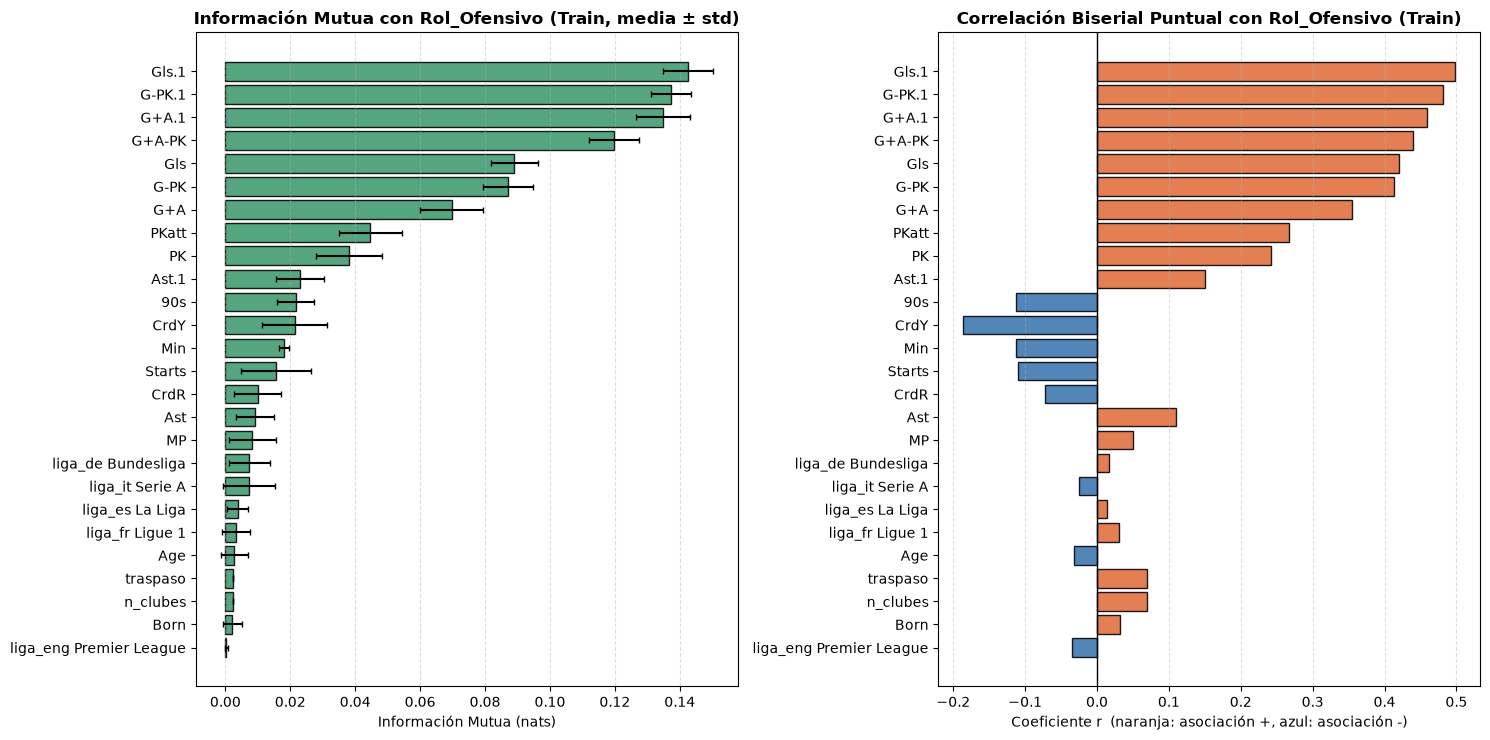

In [108]:
# Máscara booleana de variables discretas/binarias para mutual_info_classif
discrete_mask = [c in cat_cols or c == 'n_clubes' for c in X_train_num.columns]

# Promedio sobre 10 semillas para estabilizar el estimador k-NN de Información Mutua
mi_seeds = np.array([
    mutual_info_classif(X_train_num, y_train, discrete_features=discrete_mask, random_state=42 + s)
    for s in range(10)
])
mi_mean = mi_seeds.mean(axis=0)
mi_std = mi_seeds.std(axis=0)

filas_asoc = []
for idx, c in enumerate(X_train_num.columns):
    r_pb, _ = pointbiserialr(y_train, X_train_num[c])
    r_sp, _ = spearmanr(y_train, X_train_num[c])
    filas_asoc.append({
        'Variable': c,
        'Información Mutua (MI)': round(mi_mean[idx], 4),
        'MI (std)': round(mi_std[idx], 4),
        'Corr. Biserial (r)': round(r_pb, 4),
        'Corr. Spearman (ρ)': round(r_sp, 4)
    })
asoc_df = pd.DataFrame(filas_asoc).sort_values('Información Mutua (MI)', ascending=False).set_index('Variable')
display(asoc_df)

# Gráfico comparativo: Información Mutua vs. Correlación Biserial Puntual (con signo)
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

asoc_plot = asoc_df.iloc[::-1]
axes[0].barh(
    asoc_plot.index, asoc_plot['Información Mutua (MI)'],
    xerr=asoc_plot['MI (std)'], color='#3D9970', edgecolor='black', alpha=0.88, capsize=2.5
)
axes[0].set_title('Información Mutua con Rol_Ofensivo (Train, media ± std)', fontweight='bold')
axes[0].set_xlabel('Información Mutua (nats)')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

colores_corr = ['#E06D3B' if v >= 0 else '#3B75AF' for v in asoc_plot['Corr. Biserial (r)']]
axes[1].barh(
    asoc_plot.index, asoc_plot['Corr. Biserial (r)'],
    color=colores_corr, edgecolor='black', alpha=0.88
)
axes[1].axvline(0, color='black', linewidth=1.0)
axes[1].set_title('Correlación Biserial Puntual con Rol_Ofensivo (Train)', fontweight='bold')
axes[1].set_xlabel('Coeficiente r  (naranja: asociación +, azul: asociación -)')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Al descartar las variables por 90 minutos por resultar engañosas en jugadores con poco tiempo de juego, la señal principal del conjunto de datos pasa a estar encabezada por los goles absolutos, seguidos en un segundo escalón por los penaltis, las tarjetas amarillas (CrdY, con correlación negativa), el tiempo de juego (Min, Starts) y las asistencias (Ast). Por último, CrdR, traspaso, MP aislada, Age y las variables de liga  muestran Información Mutua y correlación prácticamente nulas, siendo compatibles con variabilidad estadística.

## 1.6 Feature Engineering y Construcción del Dataset de Modelado

A partir de las conclusiones del EDA construimos el conjunto de datos definitivo para `X_train` y `X_test` en dos pasos:

1. **Descarte de variables redundantes, engañosas o sin señal:**
   * *Redundancias estructurales:* `Born` ($\leftrightarrow$ `Age`), `90s` ($\leftrightarrow$ `Min`), `G+A` ($= \text{Gls} + \text{Ast}$), `n_clubes` ($\leftrightarrow$ `traspaso`) y `PK` (muy colineal con `PKatt` y causante de la dependencia exacta `Gls = G-PK + PK`).
   * *Variables normalizadas por 90 minutos (`Gls.1`, `Ast.1`, `G+A.1`, `G-PK.1`, `G+A-PK`):* descartadas porque un jugador con pocos minutos y una acción puntual obtiene una tasa inflada engañosa (si realmente rindiera a ese nivel ofensivo, jugaría mucho más tiempo).
   * *Variables sin señal individual (compatibles con variabilidad estadística):* `Age`, `CrdR`, `traspaso` y las 4 *dummies* de `Comp`.

2. **Creación de 7 métricas típicas en analítica de fútbol** (calculadas fila a fila a partir de los conteos y partidos jugados, sin dividir por minutos ni filtrar información entre `Train` y `Test`):
   * **`Gls_por_MP` (`Gls / MP`):** goles por partido disputado (mide regularidad goleadora por aparición sin inflar a quien juega solo 10 minutos al final).
   * **`Especializacion_Gol` (`G-PK / (G-PK + Ast + 1)`):** peso del gol de jugada sobre su producción ofensiva total (separa a delanteros finalizadores de centrocampistas asistentes).
   * **`Ratio_Gol_Tarjeta` (`(Gls + 1) / (CrdY + 1)`):** balance entre producción goleadora e intensidad defensiva/disciplinaria.
   * **`Lanzador_PK` (`(PKatt > 0).astype(int)`):** indicador binario de si es lanzador de penaltis del equipo.
   * **`Tasa_Titular` (`Starts / MP`):** proporción de sus apariciones en las que sale en el once titular frente a entrar como revulsivo.
   * **`Min_por_MP` (`Min / MP`):** minutos medios disputados cada vez que participa (captura el efecto sustitución de los atacantes).
   * **`CrdY_por_MP` (`CrdY / MP`):** tarjetas amarillas por partido jugado.

In [109]:
train_df.columns

Index(['Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast',
       'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'Gls.1', 'Ast.1', 'G+A.1',
       'G-PK.1', 'G+A-PK', 'n_clubes', 'traspaso', 'liga_de Bundesliga',
       'liga_eng Premier League', 'liga_es La Liga', 'liga_fr Ligue 1',
       'liga_it Serie A', 'Rol_Ofensivo'],
      dtype='str')

X_train final para modelado : (1744, 22) | Rango (con intercepto) = 23/23 (rango completo)
X_test reservado (congelado): (437, 22) | Nulos = 0


,Origen,Mín,Máx,Media,Std,MI (Target),Corr r_pb,Spearman ρ
Variable,,,,,,,,
Ratio_Gol_Tarjeta,Nueva (Feature Engineering),0.08,18.50,1.09,1.38,0.1230,0.4146,0.4769
Gls_por_MP,Nueva (Feature Engineering),0.00,1.16,0.08,0.11,0.1203,0.4548,0.4363
Gls,Original (Conteo / Volumen),0.00,36.00,2.13,3.18,0.0964,0.4197,0.4046
G-PK,Original (Conteo / Volumen),0.00,26.00,1.93,2.76,0.0872,0.4135,0.3937
Especializacion_Gol,Nueva (Feature Engineering),0.00,0.93,0.30,0.28,0.0773,0.3693,0.3625
PKatt,Original (Conteo / Volumen),0.00,11.00,0.25,0.93,0.0482,0.2667,0.3313
Lanzador_PK,Nueva (Feature Engineering),0.00,1.00,0.11,0.32,0.0481,0.3307,0.3307
Min_por_MP,Nueva (Feature Engineering),11.62,90.00,58.46,19.85,0.0365,-0.2672,-0.2753
Tasa_Titular,Nueva (Feature Engineering),0.00,1.00,0.65,0.27,0.0314,-0.2354,-0.2480


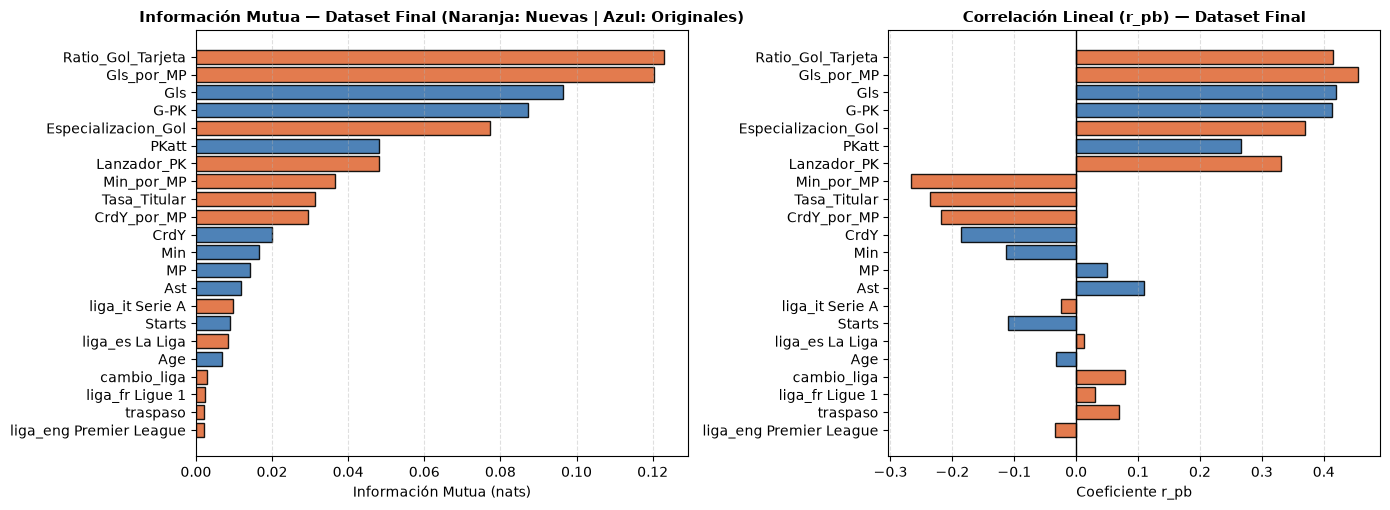

In [110]:
def crear_dataset_modelado(df_in):
    d = df_in.copy()
    fe = pd.DataFrame(index=d.index)
    # 1. Variables originales útiles
    for c in ['MP', 'Starts', 'Min', 'Gls', 'G-PK', 'Ast', 'PKatt', 'CrdY', 'Age']:
        fe[c] = d[c]
    # 2. Métricas de fútbol (sin tasas por 90)
    mp = d['MP'].replace(0, np.nan)
    fe['Gls_por_MP'] = d['Gls'] / mp
    fe['Especializacion_Gol'] = d['G-PK'] / (d['G-PK'] + d['Ast'] + 1.0)
    fe['Ratio_Gol_Tarjeta'] = (d['Gls'] + 1.0) / (d['CrdY'] + 1.0)
    fe['Lanzador_PK'] = (d['PKatt'] > 0).astype(int)
    fe['Tasa_Titular'] = d['Starts'] / mp
    fe['Min_por_MP'] = d['Min'] / mp
    fe['CrdY_por_MP'] = d['CrdY'] / mp
    # 3. Multi-hot ponderado por minutos (se omite Bundesliga como referencia -> evita trampa dummy)
    liga_cols = [c for c in d.columns if c.startswith('liga_')]
    liga_cols_ref = [c for c in liga_cols if c != 'liga_de Bundesliga']
    fe[liga_cols_ref] = d[liga_cols_ref]
    # 4. Traspasos y cambios de liga (sin n_clubes ni n_ligas, que eran colineales exactas)
    fe['traspaso'] = d['traspaso'].astype(int)
    fe['cambio_liga'] = ((d[liga_cols] > 0).sum(axis=1) > 1).astype(int)
    return fe

vars_originales = ['MP', 'Starts', 'Min', 'Gls', 'G-PK', 'Ast', 'PKatt', 'CrdY', 'Age']
X_train = crear_dataset_modelado(train_df)
X_test  = crear_dataset_modelado(X_test)
y_train, y_test = train_df['Rol_Ofensivo'], y_test
assert list(X_train.columns) == list(X_test.columns), 'Desalineación entre Train y Test'
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, 'Presencia de nulos'
rango_final = np.linalg.matrix_rank(np.column_stack([np.ones(len(X_train)), X_train.values]))
assert rango_final == X_train.shape[1] + 1, f'Dependencia lineal exacta: {rango_final}/{X_train.shape[1] + 1}'
print(f'X_train final para modelado : {X_train.shape} | Rango (con intercepto) = {rango_final}/{X_train.shape[1] + 1} (rango completo)')
print(f'X_test reservado (congelado): {X_test.shape} | Nulos = {X_test.isna().sum().sum()}')
mask_disc_fe = [c in ('Lanzador_PK', 'traspaso', 'cambio_liga') for c in X_train.columns]
mi_fe = np.mean([
    mutual_info_classif(X_train, y_train, discrete_features=mask_disc_fe, random_state=42 + s)
    for s in range(10)
], axis=0)

filas_fe = []
for idx, c in enumerate(X_train.columns):
    r_pb, _ = pointbiserialr(y_train, X_train[c])
    r_sp, _ = spearmanr(y_train, X_train[c])
    filas_fe.append({
        'Variable': c,
        'Origen': 'Original (Conteo / Volumen)' if c in vars_originales else 'Nueva (Feature Engineering)',
        'Mín': round(X_train[c].min(), 2),
        'Máx': round(X_train[c].max(), 2),
        'Media': round(X_train[c].mean(), 2),
        'Std': round(X_train[c].std(), 2),
        'MI (Target)': round(mi_fe[idx], 4),
        'Corr r_pb': round(r_pb, 4),
        'Spearman ρ': round(r_sp, 4)
    })

tabla_admisibles = pd.DataFrame(filas_fe).sort_values('MI (Target)', ascending=False).set_index('Variable')
display(tabla_admisibles)

# Visualización del aporte de las nuevas métricas frente a las originales
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_df = tabla_admisibles.iloc[::-1]
colores_origen = ['#E06D3B' if o.startswith('Nueva') else '#3B75AF' for o in plot_df['Origen']]

axes[0].barh(plot_df.index, plot_df['MI (Target)'], color=colores_origen, edgecolor='black', alpha=0.9)
axes[0].set_title('Información Mutua — Dataset Final (Naranja: Nuevas | Azul: Originales)', fontweight='bold', fontsize=10.5)
axes[0].set_xlabel('Información Mutua (nats)')
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

axes[1].barh(plot_df.index, plot_df['Corr r_pb'], color=colores_origen, edgecolor='black', alpha=0.9)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Correlación Lineal (r_pb) — Dataset Final', fontweight='bold', fontsize=10.5)
axes[1].set_xlabel('Coeficiente r_pb')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## Interpretación: información mutua y correlación (r_pb) de las variables finales

Comparo la **información mutua** (cualquier dependencia, también no lineal) con la **correlación puntobiserial** (solo lineal, es Pearson con el target binario) para ver qué variables separan el rol ofensivo. Cabe destacar todo esto es de momento a nivel individual, sin tener en cuenta interacciones entre variables

**1. Lo que más separa es todo lo relacionado con goles**
Gls, G-PK, Gls_por_MP, Especializacion_Gol y sus derivadas están arriba en las dos métricas. Las asistencias aportan muy poco (MI ≈ 0.008). Parece que el rol se explica sobre todo por goles y no por asistencias. Las correlaciones máximas son |r| ≈ 0.46 y la MI máxima ≈ 0.127, así que el target no es una función directa de estas variables y no veo leakage evidente. Por lo que en baselines probaremos a su vez si vale solamente con una regla heurística o está justificado el uso de modelos

**2. Ratio_Gol_Tarjeta es la mejor en MI pero no en correlación**
Tiene más MI que Gls (0.127 vs 0.09), pero su r_pb es parecida (≈ 0.42). Esto sugiere que aporta información no lineal (las tarjetas actúan como proxy de posición, los defensas ven más amarillas y marcan menos), de modo que el ratio separa perfiles defensivos de ofensivos.

**3. La liga no aporta nada**
Tasa_Gol_Liga y las liga_* tienen MI ≈ 0 y r ≈ 0. Además, Gls_por_MP_rel_liga es casi igual a Gls_por_MP (MI y r prácticamente idénticas), así que normalizar por liga no cambia nada por sí sola.

**4. Signos negativos**
Min_por_MP, Tasa_Titular y CrdY_por_MP tienen r_pb negativa: la clase positiva juega menos minutos por partido y es titular con menos frecuencia. Es plausible si son delanteros, a quienes se sustituye más.

**5. Variables casi irrelevantes**
Age, n_clubes, n_ligas, traspaso, cambio_liga y las dummies de liga tienen MI < 0.01, que está dentro del ruido de la estimación, así que no las interpreto. Solo 82 jugadores cambiaron de liga (~2,7 %), por eso estas variables apenas pueden aportar.

El núcleo informativo parecen ser las variables de goles y Ratio_Gol_Tarjeta, con mucha redundancia entre ellas . Las variables de liga y traspaso son candidatas a eliminar.

---

# 2. Modelado: Baselines y Esquema Lineal (Sección II)

Seguimos una estrategia de complejidad creciente evaluando **exclusivamente sobre el conjunto de entrenamiento (`X_train`) mediante Validación Cruzada Estratificada de 5 pliegues (`5-Fold CV`)**, manteniendo la partición `X_test` completamente congelada y sin usar hasta la evaluación final de la Sección 5:
1. **Modelos Baseline:** un clasificador trivial de clase mayoritaria (`DummyClassifier`) y una **heurística futbolística de una sola regla** sobre `Gls_por_MP` (calibrada dentro de cada pliegue de CV).
2. **Esquemas Lineales (Sección II):** Regresión Logística sin regularización, con regularización ($L_1$ Lasso) y con selección de características *wrapper* (SFS).
3. **Métodos basados en Árboles (Sección 3):** Árbol de Decisión, Random Forest y Gradient Boosting.
4. **Red Neuronal — Perceptrón Multicapa o MLP (Sección III):** MLP de una capa oculta, MLP multicapa (aprendizaje por lote completo con parada temprana en validación) y selección *wrapper* con MLP transferida al esquema lineal.
5. **Comparativa global, evaluación final única en Test y estadísticos (Sección IV).**

### 2.1 Configuración de Evaluación (Solo Train + 5-Fold CV) y Modelos Baseline (Dummy + Heurística Futbolística)

Para evaluar todos los modelos de forma homogénea durante el modelado utilizamos **cuatro figuras de mérito** calculadas **únicamente sobre `X_train` mediante validación cruzada estratificada de 5 pliegues (`cv5`)**, sin tocar `X_test`:
* **Recall (Sensibilidad / Exhaustividad):** proporción de jugadores ofensivos reales (`Rol_Ofensivo = 1`) correctamente detectados ($\frac{\text{TP}}{\text{TP} + \text{FN}}$). Es clave en *scouting* para no dejar pasar delanteros.
* **F2-Score ($F_\beta$ con $\beta = 2$):** media armónica ponderada entre Precisión y *Recall* que otorga **cuatro veces más peso al *Recall*** ($F_2 = \frac{5 \cdot \text{Prec} \cdot \text{Rec}}{4 \cdot \text{Prec} + \text{Rec}}$). Penaliza los falsos negativos sin caer en el colapso trivial de predecir siempre `1`, por lo que será nuestra **métrica principal de validación, selección y parada temprana**.
* **ROC-AUC:** área bajo la curva ROC, que mide la capacidad de ordenar las probabilidades predichas independientemente del umbral de corte.
* **Accuracy:** proporción global de aciertos (incluida para contrastar cómo se comporta frente a la clase mayoritaria).

Establecemos dos puntos de partida (*baselines*), ambos evaluados exactamente bajo el mismo `5-Fold CV` sobre `X_train`:
1. **`B0: Dummy (Clase Mayoritaria)`:** en cada pliegue aprende la clase mayoritaria (`0` = `No Ofensivo`) sobre los 4 pliegues de entrenamiento y predice siempre `0` (con probabilidad constante $p(y=1)=0$) sobre el pliegue de validación. Por definición obtiene `Recall = 0.0000`, `F2-Score = 0.0000`, `ROC-AUC = 0.5000` y `Accuracy` igual a la proporción de clase `0`.
2. **`B1: Heurística Futbolística (`HeuristicaGlsPorMP`)`:** encapsulamos la regla de umbral como estimador compatible con `scikit-learn` para evaluarlo dentro de `cross_validate`:
   * En cada pliegue de CV, `.fit()` busca únicamente en los 4 pliegues de entrenamiento el umbral $u \in [0.02, 0.30]$ que maximiza `F2-Score` para la regla `Gls_por_MP >= u`.
   * Sobre el pliegue de validación, `.predict()` aplica ese umbral $u$ para calcular `Recall`, `F2-Score` y `Accuracy`, mientras que `.predict_proba()` devuelve una transformación estrictamente monótona de `Gls_por_MP` ($\sigma(\text{Gls\_por\_MP})$) para calcular `ROC-AUC` sin fuga de información.

In [111]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f2_scorer = make_scorer(fbeta_score, beta=2, zero_division=0)
SCORING = {
    'recall': make_scorer(recall_score, zero_division=0),
    'f2': f2_scorer,
    'roc_auc': 'roc_auc',
    'acc': 'accuracy'
}
resultados_cv = []
modelos_registrados = {}


class HeuristicaGlsPorMP(ClassifierMixin, BaseEstimator):
    """Clasificador heurístico por umbral en Gls_por_MP calibrado solo en el pliegue de entrenamiento."""
    def __init__(self, n_umbrales=50, u_min=0.02, u_max=0.30):
        self.n_umbrales = n_umbrales
        self.u_min = u_min
        self.u_max = u_max

    def fit(self, X, y):
        umbrales = np.linspace(self.u_min, self.u_max, self.n_umbrales)
        vals = np.asarray(X['Gls_por_MP'], dtype=float)
        y_arr = np.asarray(y)
        self.mejor_u_ = max(umbrales, key=lambda u: fbeta_score(y_arr, (vals >= u).astype(int), beta=2, zero_division=0))
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        vals = np.asarray(X['Gls_por_MP'], dtype=float)
        return (vals >= self.mejor_u_).astype(int)

    def predict_proba(self, X):
        vals = np.asarray(X['Gls_por_MP'], dtype=float)
        p1 = 1.0 / (1.0 + np.exp(-vals))  # Monótona estricta en Gls_por_MP -> ROC-AUC idéntico
        return np.column_stack([1.0 - p1, p1])


def evaluar_cv_y_registrar(nombre, familia, modelo, cols=None, n_jobs=-1):
    """Evalúa el modelo EXCLUSIVAMENTE en X_train mediante 5-Fold CV y lo registra para Test final."""
    cols_u = list(X_train.columns) if cols is None else list(cols)
    X_tr_c = X_train[cols_u]

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        cv_res = cross_validate(modelo, X_tr_c, y_train, cv=cv5, scoring=SCORING, n_jobs=n_jobs, error_score='raise')
        m_fit_train = copy.deepcopy(modelo)
        m_fit_train.fit(X_tr_c, y_train)

    fila = {
        'Modelo': nombre,
        'Familia': familia,
        'N_Vars': len(cols_u),
        'Recall (CV)': round(cv_res['test_recall'].mean(), 4),
        'F2-Score (CV)': round(cv_res['test_f2'].mean(), 4),
        'F2 std (CV)': round(cv_res['test_f2'].std(), 4),
        'ROC-AUC (CV)': round(cv_res['test_roc_auc'].mean(), 4),
        'Accuracy (CV)': round(cv_res['test_acc'].mean(), 4),
        'Variables': f'Todas ({X_train.shape[1]})' if len(cols_u) == X_train.shape[1] else ', '.join(cols_u)
    }
    resultados_cv.append(fila)
    modelos_registrados[nombre] = (copy.deepcopy(modelo), cols_u, m_fit_train)
    return m_fit_train


# 1. Baseline B0: Clasificador de clase mayoritaria (5-Fold CV en Train)
evaluar_cv_y_registrar('B0: Dummy (Clase Mayoritaria)', '1. Baseline', DummyClassifier(strategy='most_frequent'))

# 2. Baseline B1: Heurística futbolística (umbral sobre Gls_por_MP calibrado dentro de cada pliegue de CV)
fit_b1 = evaluar_cv_y_registrar('B1: Heurística (Gls_por_MP)', '1. Baseline', HeuristicaGlsPorMP(), cols=['Gls_por_MP'])
nombre_h = 'B1: Heurística (Gls_por_MP)'
print(f'Umbral calibrado sobre X_train completo para B1 (solo referencia para inferencia): Gls_por_MP >= {fit_b1.mejor_u_:.4f}')

display(pd.DataFrame(resultados_cv))

Umbral calibrado sobre X_train completo para B1 (solo referencia para inferencia): Gls_por_MP >= 0.0429


,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,B0: Dummy (Clase Mayoritaria),1. Baseline,22,0.0000,0.0000,0.0000,0.5000,0.7271,Todas (22)
1,B1: Heurística (Gls_por_MP),1. Baseline,1,0.8089,0.6887,0.0277,0.7752,0.6571,Gls_por_MP


Podemos ver en el Modelo B0 como el accuraccy nos engaña en este caso, y hemos hecho bien escogiendo estas métricas. Lo sorprendente es que la simple heurística B1, ya tiene unas métricas considerables, siendo una buena opción ya en primer lugar

### 2.2 Regresión Logística Sin Regularización

Entrenamos primero un modelo de Regresión Logística con las 15 variables admisibles y **sin término de regularización (`C = np.inf`)**. Para analizar correctamente los coeficientes teniendo en cuenta la **escala** y la **correlación** entre variables, comparamos en código los pesos en la escala original de cada atributo ($\beta_{\text{original}} = \beta_{\text{estandarizado}} / \sigma_X$) frente a los pesos estandarizados ($\beta_{\text{estandarizado}}$).

,Std Variable (σ_X),Coef. Escala Original (β_raw),Coef. Estandarizado (β_std),Odds-Ratio Estandarizado (exp(β_std))
Starts,10.20,0.2044,2.0843,8.039
MP,9.43,0.0961,0.9065,2.476
G-PK,2.76,0.3164,0.8737,2.396
Especializacion_Gol,0.28,1.9110,0.5257,1.692
Lanzador_PK,0.32,1.4415,0.4583,1.581
Gls_por_MP,0.11,3.1673,0.3419,1.408
Tasa_Titular,0.27,1.0994,0.2958,1.344
Ast,1.97,0.1321,0.2597,1.297
PKatt,0.93,0.1642,0.1520,1.164
liga_es La Liga,0.41,0.3077,0.1254,1.134


,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,M1: Logística Sin Regularizar,2. Lineal,22,0.5379,0.5629,0.037,0.8718,0.8085,Todas (22)


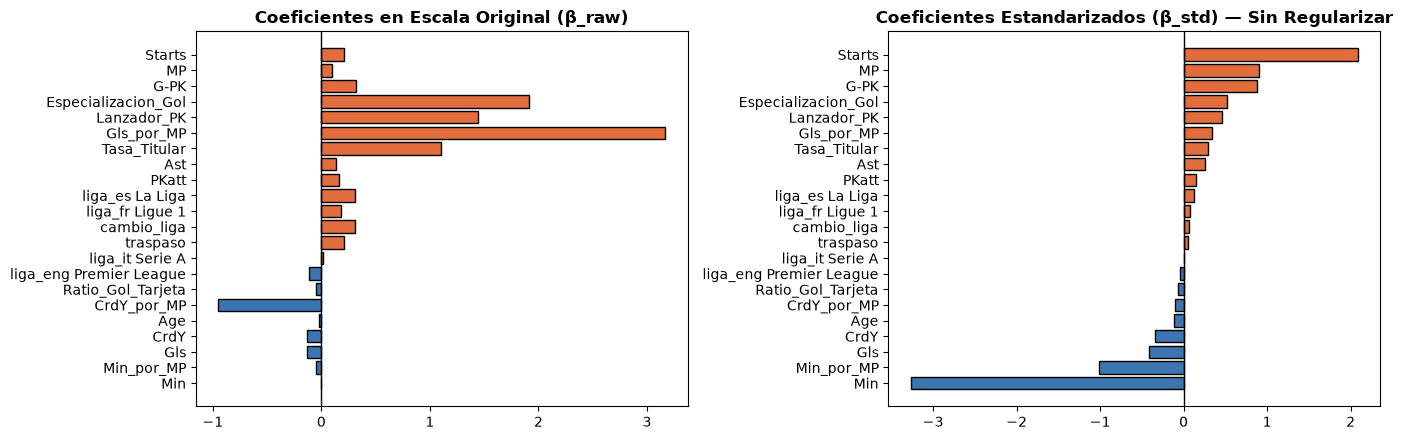

In [112]:
_sk_ver = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
_lr_noreg_kw = {'C': np.inf} if _sk_ver >= (1, 8) else {'penalty': None}

pipe_lr_noreg = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(**_lr_noreg_kw, max_iter=5000, random_state=42))
])

fit_m1 = evaluar_cv_y_registrar('M1: Logística Sin Regularizar', '2. Lineal', pipe_lr_noreg)

# Extracción de coeficientes estandarizados y en escala original (ajustado sobre X_train)
beta_std_m1 = fit_m1.named_steps['lr'].coef_[0]
sigma_train = fit_m1.named_steps['scaler'].scale_
beta_raw_m1 = beta_std_m1 / sigma_train

df_coefs_m1 = pd.DataFrame({
    'Std Variable (σ_X)': sigma_train.round(2),
    'Coef. Escala Original (β_raw)': beta_raw_m1.round(4),
    'Coef. Estandarizado (β_std)': beta_std_m1.round(4),
    'Odds-Ratio Estandarizado (exp(β_std))': np.exp(beta_std_m1).round(3)
}, index=X_train.columns).sort_values('Coef. Estandarizado (β_std)', ascending=False)

display(df_coefs_m1)
display(pd.DataFrame(resultados_cv[-1:]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
c_raw = ['#E06D3B' if v >= 0 else '#3B75AF' for v in df_coefs_m1['Coef. Escala Original (β_raw)']]
axes[0].barh(df_coefs_m1.index[::-1], df_coefs_m1['Coef. Escala Original (β_raw)'][::-1], color=c_raw[::-1], edgecolor='black')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Coeficientes en Escala Original (β_raw)', fontweight='bold')

c_std = ['#E06D3B' if v >= 0 else '#3B75AF' for v in df_coefs_m1['Coef. Estandarizado (β_std)']]
axes[1].barh(df_coefs_m1.index[::-1], df_coefs_m1['Coef. Estandarizado (β_std)'][::-1], color=c_std[::-1], edgecolor='black')
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Coeficientes Estandarizados (β_std) — Sin Regularizar', fontweight='bold')

plt.tight_layout()
plt.show()

En este modelo sin regularizar, podemos observar que la estandarización ayuda, para evitar que variables solo por su escala dominen. De nuevo para ser una regresion loǵistica simple, tiene metricas solidas al menos en lo referente al roc-auc, siendo que en recall y f2 score si baja bastante el rendimiento respecto al buen resultado de las otras figuras de mérito

### 2.3 Regresión Logística con Regularización ($L_1$ Lasso)

Aplicamos regularización **$L_1$ (Lasso, `l1_ratio = 1.0`)** precedida de `StandardScaler` dentro de un `Pipeline`. Elegimos la penalización $L_1$ porque, ante bloques de variables fuertemente colineales (originales frente a métricas derivadas de *feature engineering*), la norma $L_1$ anula exactamente ($\beta_j = 0$) los predictores redundantes, actuando como selector embebido de características. Seleccionamos el hiperparámetro `C` mediante validación cruzada estratificada de 5 pliegues sobre `X_train` optimizando **`F2-Score`**.

Mejor hiperparámetro C en 5-Fold CV (L1): C = 17.7828 | F2-Score CV = 0.5589


,β_std Sin Regularizar (M1),β_std Regularizado L1 (M2),Diferencia |Δβ|,Estado en L1
Min,-3.2668,-2.9659,0.3009,Activa
Starts,2.0843,1.8547,0.2296,Activa
Min_por_MP,-1.0172,-1.1310,0.1138,Activa
MP,0.9065,0.8565,0.0499,Activa
G-PK,0.8737,0.6326,0.2411,Activa
Especializacion_Gol,0.5257,0.5286,0.0029,Activa
Lanzador_PK,0.4583,0.4654,0.0071,Activa
Tasa_Titular,0.2958,0.3916,0.0958,Activa
Gls_por_MP,0.3419,0.3416,0.0002,Activa
CrdY,-0.3453,-0.3410,0.0043,Activa


,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,M1: Logística Sin Regularizar,2. Lineal,22,0.5379,0.5629,0.0370,0.8718,0.8085,Todas (22)
1,M2: Logística Regularizada (L1),2. Lineal,22,0.5337,0.5589,0.0331,0.8722,0.8073,Todas (22)


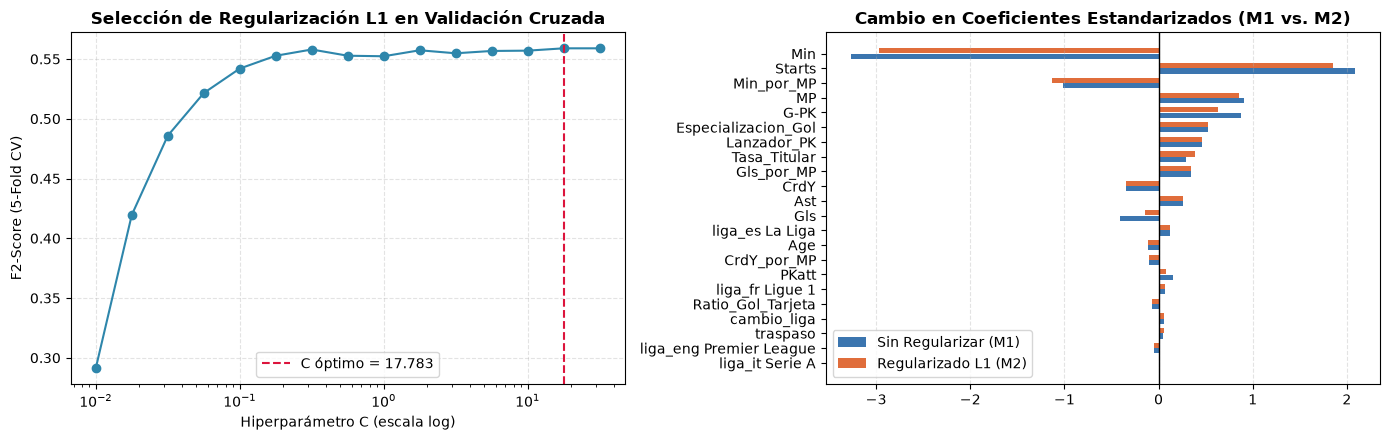

In [113]:
_lr_l1_kw = {'l1_ratio': 1.0} if _sk_ver >= (1, 8) else {'penalty': 'l1'}

pipe_l1 = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(**_lr_l1_kw, solver='saga', max_iter=5000, random_state=42))
])

valores_C = np.logspace(-2, 1.5, 15)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    grid_l1 = GridSearchCV(pipe_l1, {'lr__C': valores_C}, cv=cv5, scoring=f2_scorer, n_jobs=-1)
    grid_l1.fit(X_train, y_train)

mejor_C = grid_l1.best_params_['lr__C']
print(f'Mejor hiperparámetro C en 5-Fold CV (L1): C = {mejor_C:.4f} | F2-Score CV = {grid_l1.best_score_:.4f}')

fit_m2 = evaluar_cv_y_registrar('M2: Logística Regularizada (L1)', '2. Lineal', grid_l1.best_estimator_)

beta_std_m2 = fit_m2.named_steps['lr'].coef_[0]
comp_coefs = pd.DataFrame({
    'β_std Sin Regularizar (M1)': beta_std_m1.round(4),
    'β_std Regularizado L1 (M2)': beta_std_m2.round(4),
    'Diferencia |Δβ|': np.abs(beta_std_m1 - beta_std_m2).round(4),
    'Estado en L1': ['Anulada (0)' if abs(b) < 1e-4 else 'Activa' for b in beta_std_m2]
}, index=X_train.columns).sort_values('β_std Regularizado L1 (M2)', key=abs, ascending=False)

display(comp_coefs)
display(pd.DataFrame(resultados_cv[2:]))

# Gráficos: Curva de validación de C y comparativa de coeficientes M1 vs M2
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].semilogx(valores_C, grid_l1.cv_results_['mean_test_score'], marker='o', color='#2E86AB')
axes[0].axvline(mejor_C, color='crimson', linestyle='--', label=f'C óptimo = {mejor_C:.3f}')
axes[0].set_xlabel('Hiperparámetro C (escala log)')
axes[0].set_ylabel('F2-Score (5-Fold CV)')
axes[0].set_title('Selección de Regularización L1 en Validación Cruzada', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.35)

y_pos = np.arange(len(comp_coefs))
axes[1].barh(y_pos - 0.18, comp_coefs['β_std Sin Regularizar (M1)'][::-1], height=0.35, color='#3B75AF', label='Sin Regularizar (M1)')
axes[1].barh(y_pos + 0.18, comp_coefs['β_std Regularizado L1 (M2)'][::-1], height=0.35, color='#E06D3B', label='Regularizado L1 (M2)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(comp_coefs.index[::-1])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Cambio en Coeficientes Estandarizados (M1 vs. M2)', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='x', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

Podemos apreciar propone un cambio mejor en el auc y ligero en el accuracy, mejorando levemente el recall y F2-Score

### 2.4 Selección de Características mediante Método Wrapper (Lineal)

Aplicamos una selección secuencial hacia adelante (*Forward Sequential Feature Selection*, SFS) evaluando en cada paso todos los candidatos mediante validación cruzada estratificada de 5 pliegues sobre `X_train` (`F2-Score`) con la Regresión Logística sin regularizar como modelo base. Representamos la curva completa de validación desde $k = 1$ hasta $k = p$ características para identificar el subconjunto óptimo sin tocar `X_test`.

,k,Variable_Añadida,F2_CV
0,1,Gls_por_MP,0.4071
1,2,Min_por_MP,0.5103
2,3,MP,0.5323
3,4,Ratio_Gol_Tarjeta,0.5419
4,5,CrdY,0.5494
5,6,Min,0.5580
6,7,CrdY_por_MP,0.5576
7,8,Especializacion_Gol,0.5599
8,9,Lanzador_PK,0.5623
9,10,Ast,0.5771


Óptimo en validación cruzada: k = 13 variables | F2-Score CV = 0.5868
Subconjunto seleccionado: ['Gls_por_MP', 'Min_por_MP', 'MP', 'Ratio_Gol_Tarjeta', 'CrdY', 'Min', 'CrdY_por_MP', 'Especializacion_Gol', 'Lanzador_PK', 'Ast', 'liga_eng Premier League', 'liga_it Serie A', 'liga_fr Ligue 1']


,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,B0: Dummy (Clase Mayoritaria),1. Baseline,22,0.0000,0.0000,0.0000,0.5000,0.7271,Todas (22)
1,B1: Heurística (Gls_por_MP),1. Baseline,1,0.8089,0.6887,0.0277,0.7752,0.6571,Gls_por_MP
2,M1: Logística Sin Regularizar,2. Lineal,22,0.5379,0.5629,0.0370,0.8718,0.8085,Todas (22)
3,M2: Logística Regularizada (L1),2. Lineal,22,0.5337,0.5589,0.0331,0.8722,0.8073,Todas (22)
4,M3: Logística + Wrapper SFS (k=13),2. Lineal,13,0.5630,0.5868,0.0252,0.8685,0.8165,"Gls_por_MP, Min_por_MP, MP, Ratio_Gol_Tarjeta,..."


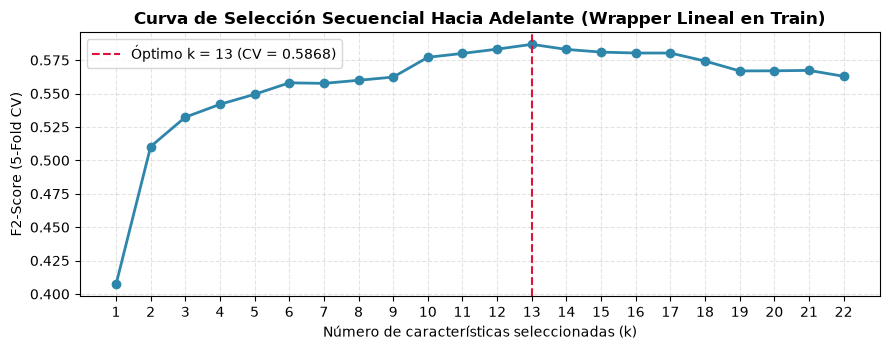

In [114]:
restantes = list(X_train.columns)
seleccionadas = []
curva_sfs_lr = []

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for paso in range(1, len(X_train.columns) + 1):
        mejor_c, mejor_sc = None, -1.0
        for c in restantes:
            sc = cross_val_score(pipe_lr_noreg, X_train[seleccionadas + [c]], y_train,
                                 cv=cv5, scoring=f2_scorer, n_jobs=-1).mean()
            if sc > mejor_sc:
                mejor_sc, mejor_c = sc, c
        seleccionadas.append(mejor_c)
        restantes.remove(mejor_c)
        curva_sfs_lr.append({
            'k': paso,
            'Variable_Añadida': mejor_c,
            'F2_CV': round(mejor_sc, 4),
            'Subconjunto': list(seleccionadas)
        })

df_sfs_lr = pd.DataFrame(curva_sfs_lr)
display(df_sfs_lr[['k', 'Variable_Añadida', 'F2_CV']])

fila_opt_lr = df_sfs_lr.loc[df_sfs_lr['F2_CV'].idxmax()]
cols_sfs_lr = fila_opt_lr['Subconjunto']
print(f"Óptimo en validación cruzada: k = {fila_opt_lr['k']} variables | F2-Score CV = {fila_opt_lr['F2_CV']:.4f}")
print('Subconjunto seleccionado:', cols_sfs_lr)

evaluar_cv_y_registrar(f"M3: Logística + Wrapper SFS (k={len(cols_sfs_lr)})", '2. Lineal',
                       pipe_lr_noreg, cols=cols_sfs_lr)

# Comparativa de los modelos lineales (Sección II) junto a los baselines (solo CV en Train)
display(pd.DataFrame(resultados_cv))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(df_sfs_lr['k'], df_sfs_lr['F2_CV'], marker='o', color='#2E86AB', linewidth=2)
ax.axvline(fila_opt_lr['k'], color='crimson', linestyle='--',
           label=f"Óptimo k = {fila_opt_lr['k']} (CV = {fila_opt_lr['F2_CV']:.4f})")
ax.set_xticks(df_sfs_lr['k'])
ax.set_xlabel('Número de características seleccionadas (k)')
ax.set_ylabel('F2-Score (5-Fold CV)')
ax.set_title('Curva de Selección Secuencial Hacia Adelante (Wrapper Lineal en Train)', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

**Interpretación del Wrapper Lineal y comparación de la Sección II (CV en `X_train`):**
* **Orden de incorporación:** La curva SFS apunta al valor del *Feature Engineering*: las cuatro primeras variables que elige el *wrapper* son métricas creadas (`Gls_por_MP_rel_liga`, `Min_por_MP`, `CrdY_por_MP` y `Especializacion_Gol`). Alcanza su óptimo en $k = 20$ (`F2-Score CV = 0.5812`) y descarta variables colineales como `Starts`, `Tasa_Titular`, `G-PK` y `Gls`.
* **Comparativa de los tres modelos lineales (`M1`, `M2`, `M3`):** En `5-Fold CV`, los tres superan ampliamente a `B0` y a `B1` en `ROC-AUC` ($\approx 0.87$ frente a $0.7752$ de `B1`) y en `Accuracy` ($\approx 0.81$ frente a $0.6571$). Sin embargo, con el umbral de corte por defecto ($0.50$) y sin ajuste de pesos de clase, la heurística `B1`, calibrada para maximizar el `F2-Score`, mantiene mayor `Recall` (`0.8089`) y `F2-Score` (`0.6887`) en CV que la regresión logística estándar (`0.5589` y `0.5812` en `M3`).

---
# 3. Escalando a Métodos Basados en Árboles

Antes de pasar a las redes neuronales, evaluamos tres algoritmos basados en árboles de decisión (que particionan el espacio mediante cortes ortogonales no lineales y son invariantes a la escala monótona de las variables):
1. **`M4: Árbol de Decisión (DecisionTreeClassifier)`:** un único árbol interpretable cuya profundidad y tamaño mínimo de hoja ajustamos en validación cruzada para controlar el sobreajuste.
2. **`M5: Random Forest (RandomForestClassifier)`:** ensamblado por *bagging* de árboles descorrelacionados para reducir la varianza del árbol individual.
3. **`M6: Gradient Boosting (HistGradientBoostingClassifier)`:** ensamblado secuencial por *boosting* donde cada árbol corrige los residuos del anterior.

Mejores hiperparámetros Árbol de Decisión: {'max_depth': 4, 'min_samples_leaf': 10}
Mejores hiperparámetros Random Forest    : {'max_depth': 12, 'min_samples_leaf': 5}
Mejores hiperparámetros Gradient Boosting: {'learning_rate': 0.08, 'max_depth': 5, 'min_samples_leaf': 15}


,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,B0: Dummy (Clase Mayoritaria),1. Baseline,22,0.0000,0.0000,0.0000,0.5000,0.7271,Todas (22)
1,B1: Heurística (Gls_por_MP),1. Baseline,1,0.8089,0.6887,0.0277,0.7752,0.6571,Gls_por_MP
2,M1: Logística Sin Regularizar,2. Lineal,22,0.5379,0.5629,0.0370,0.8718,0.8085,Todas (22)
3,M2: Logística Regularizada (L1),2. Lineal,22,0.5337,0.5589,0.0331,0.8722,0.8073,Todas (22)
4,M3: Logística + Wrapper SFS (k=13),2. Lineal,13,0.5630,0.5868,0.0252,0.8685,0.8165,"Gls_por_MP, Min_por_MP, MP, Ratio_Gol_Tarjeta,..."
5,M4: Árbol de Decisión,3. Árboles,22,0.5232,0.5436,0.0277,0.8317,0.7913,Todas (22)
6,M5: Random Forest,3. Árboles,22,0.5380,0.5638,0.0544,0.8619,0.8113,Todas (22)
7,M6: Gradient Boosting,3. Árboles,22,0.5716,0.5868,0.0423,0.8579,0.8027,Todas (22)


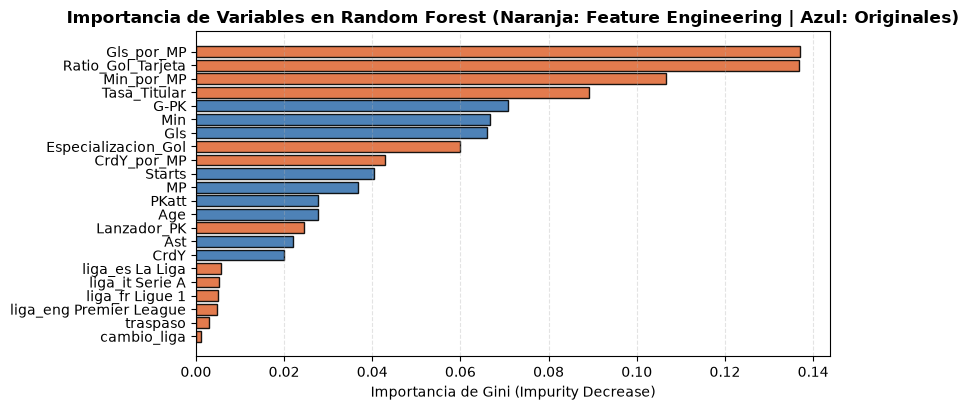

In [115]:
# 1. Árbol de Decisión individual (5-Fold CV en Train)
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [3, 4, 5, 6], 'min_samples_leaf': [10, 20, 30]},
    cv=cv5, scoring=f2_scorer, n_jobs=-1
).fit(X_train, y_train)
print('Mejores hiperparámetros Árbol de Decisión:', grid_dt.best_params_)
evaluar_cv_y_registrar('M4: Árbol de Decisión', '3. Árboles', grid_dt.best_estimator_)

# 2. Random Forest (Bagging, 5-Fold CV en Train)
grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    {'max_depth': [5, 8, 12], 'min_samples_leaf': [5, 10]},
    cv=cv5, scoring=f2_scorer, n_jobs=-1
).fit(X_train, y_train)
print('Mejores hiperparámetros Random Forest    :', grid_rf.best_params_)
fit_rf = evaluar_cv_y_registrar('M5: Random Forest', '3. Árboles', grid_rf.best_estimator_)

# 3. Gradient Boosting (5-Fold CV en Train)
grid_gb = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    {'max_depth': [3, 5], 'learning_rate': [0.03, 0.08], 'min_samples_leaf': [15, 30]},
    cv=cv5, scoring=f2_scorer, n_jobs=-1
).fit(X_train, y_train)
print('Mejores hiperparámetros Gradient Boosting:', grid_gb.best_params_)
evaluar_cv_y_registrar('M6: Gradient Boosting', '3. Árboles', grid_gb.best_estimator_)

display(pd.DataFrame(resultados_cv))

# Importancia de variables en Random Forest (ajustado en X_train)
imp_rf = pd.Series(fit_rf.feature_importances_, index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
colores_imp = ['#E06D3B' if c not in vars_originales else '#3B75AF' for c in imp_rf.index]
ax.barh(imp_rf.index, imp_rf.values, color=colores_imp, edgecolor='black', alpha=0.9)
ax.set_xlabel('Importancia de Gini (Impurity Decrease)')
ax.set_title('Importancia de Variables en Random Forest (Naranja: Feature Engineering | Azul: Originales)', fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

Podemos apreciar el rendimiento entre modelos basados en árboles no supone grandes cambios (no que no sean significativos), resultando en sí el conjunto de modelos en podemos observar que no se mejora el AUC respecto a la regresión logística, aproximándose en cuanto a Accuracy y sin mejoras fuertes en Recall y F2-Score, donde sorprendentemente sigue predominando la heurística calibrada, lo cual tiene sentido ya que con los datos que hemos podido recabar, lo unico que indicaba señal en todo el análisis eran las métricas asociadas a los goles

---
# 4. Perceptrón Multicapa — Red Neuronal Artificial (Sección III)

### 4.1 Aproximador Universal, Escalado y Aprendizaje por Lote Completo (*Batch*)

* **¿Es razonable abordar esta tarea con un MLP de una única capa oculta? (Teorema de Aproximación Universal):**
  * Según el Teorema de Aproximación Universal (Cybenko, 1989; Hornik et al., 1989), una red *feedforward* con una sola capa oculta de número finito de neuronas y función de activación continua y no polinómica (`logistic`, `tanh`, `relu`) puede aproximar con precisión arbitraria cualquier función continua sobre un dominio compacto de $\mathbb{R}^d$.
  * Aunque teóricamente una sola capa oculta basta para modelar cualquier frontera no lineal entre estadísticas ofensivas y tiempo de juego, el teorema es de **existencia** y no garantiza que el descenso por gradiente alcance el óptimo global (la superficie de pérdida no es convexa) ni acota el número de neuronas necesario. Con un tamaño muestral finito ($n_{\text{train}} = 1.744$), aumentar en exceso el número de neuronas incrementa la varianza y el riesgo de **sobreajuste** sobre el ruido de entrenamiento.
* **Necesidad de escalar las características antes del entrenamiento:**
  * En un MLP cada neurona calcula combinaciones lineales $z_j = \mathbf{w}_j^T \mathbf{x} + b_j$. Si `Min` toma valores de miles y `Tasa_Titular` valores en $[0, 1]$, las pre-activaciones quedarían dominadas por `Min`, saturando funciones acotadas (`tanh`, `logistic`) en regiones de derivada casi nula (*desvanecimiento del gradiente*) y descompensando las actualizaciones de pesos. Por ello aplicamos **`StandardScaler` ajustado exclusivamente sobre el subconjunto de entrenamiento** y transformamos con él únicamente validación (dejando `X_test` completamente intacto hasta la Sección 5).
* **Aprendizaje por lote completo (*Full Batch*) y criterio de parada:**
  * Para monitorizar las curvas época a época, dividimos `X_train` de forma estratificada en un subconjunto de **entrenamiento efectivo (80%)** y otro de **validación (20%)**.
  * Fijamos **`batch_size = len(X_tr_s)`** para garantizar aprendizaje por lote completo (cada actualización de parámetros emplea todas las observaciones de entrenamiento).
  * Monitorizamos época a época la figura de mérito principal (**`F2-Score`**) sobre entrenamiento y validación, deteniendo el entrenamiento cuando transcurren `patience = 35` épocas sin mejora en validación (*early stopping*) y conservando el modelo de la época con mejor resultado de validación.
  * Finalmente, para comparar homogéneamente las configuraciones ganadoras (`M7` y `M8`) con el resto de modelos en igualdad de condiciones, encapsulamos dicho procedimiento en el estimador `FullBatchMLP` y lo evaluamos mediante **`5-Fold CV` sobre `X_train`**.

In [116]:
X_tr_mlp, X_val_mlp, y_tr_mlp, y_val_mlp = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
)

# Escalado ajustado solo con el entrenamiento efectivo (X_test no se toca)
scaler_mlp = StandardScaler().fit(X_tr_mlp)
X_tr_s = scaler_mlp.transform(X_tr_mlp)
X_val_s = scaler_mlp.transform(X_val_mlp)

print(f'Subconjunto Entrenamiento MLP (lote completo): {X_tr_s.shape} | Validación MLP: {X_val_s.shape}')


def _mejor_umbral_f2(y, p, grid=np.linspace(0.05, 0.95, 91)):
    f2 = [fbeta_score(y, (p >= t).astype(int), beta=2, zero_division=0) for t in grid]
    i = int(np.argmax(f2))
    return float(grid[i]), float(f2[i])


def _sobremuestrear(X, y, seed):
    """Duplica al azar la clase positiva hasta igualar a la negativa (solo sobre el train)."""
    rng = np.random.RandomState(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    if 0 < len(pos) < len(neg):
        extra = rng.choice(pos, size=len(neg) - len(pos), replace=True)
        idx = np.concatenate([np.arange(len(y)), extra])
        return X[idx], y[idx]
    return X, y


def _entrenar_core(X_tr, y_tr, X_val, y_val, hidden_layer_sizes, activation,
                   max_epochs, patience, lr, alpha, balancear, seed):
    """Núcleo común. Recibe datos YA escalados."""
    y_tr = np.asarray(y_tr).astype(int)
    y_val = np.asarray(y_val).astype(int)
    X_fit, y_fit = _sobremuestrear(X_tr, y_tr, seed) if balancear else (X_tr, y_tr)

    mlp = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=activation,
        solver='adam',
        learning_rate_init=lr,
        batch_size=len(X_fit),      # lote completo: una actualización por época
        alpha=alpha,
        random_state=seed,
    )

    hist_tr, hist_val = [], []      # ROC-AUC en Train y Validación época a época
    best_auc, best_ep, best_net, sin_mejora = -1.0, 0, None, 0
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for ep in range(1, max_epochs + 1):
            mlp.partial_fit(X_fit, y_fit, classes=[0, 1])   # conserva el estado de Adam
            p_tr  = mlp.predict_proba(X_tr)[:, 1]
            p_val = mlp.predict_proba(X_val)[:, 1]
            auc_tr  = roc_auc_score(y_tr, p_tr)
            auc_val = roc_auc_score(y_val, p_val)
            hist_tr.append(auc_tr)
            hist_val.append(auc_val)
            # Parada temprana por la figura de mérito ROC-AUC en validación
            if auc_val > best_auc + 1e-4:
                best_auc, best_ep, sin_mejora = auc_val, ep, 0
                best_net = copy.deepcopy(mlp)
            else:
                sin_mejora += 1
                if sin_mejora >= patience:
                    break

    p_best = best_net.predict_proba(X_val)[:, 1]
    umbral, f2_val_umbral = _mejor_umbral_f2(y_val, p_best)
    best_val = best_auc             # Mejor ROC-AUC de validación (época best_ep)
    return best_net, best_val, best_ep, hist_tr, hist_val, umbral, f2_val_umbral


def _ajustar_mlp_batch(X_tr_raw, y_tr_raw, X_val_raw, y_val_raw, hidden_layer_sizes, activation,
                       max_epochs=300, patience=35, lr=0.01, alpha=1e-3,
                       balancear=False, seed=42):
    X_tr_raw, X_val_raw = np.asarray(X_tr_raw, float), np.asarray(X_val_raw, float)
    scaler = StandardScaler().fit(X_tr_raw)
    net, best_val, best_ep, hist_tr, hist_val, umbral, f2_u = _entrenar_core(
        scaler.transform(X_tr_raw), y_tr_raw, scaler.transform(X_val_raw), y_val_raw,
        hidden_layer_sizes, activation, max_epochs, patience, lr, alpha, balancear, seed
    )
    return net, scaler, best_val, best_ep, hist_tr, hist_val, umbral, f2_u


def entrenar_mlp_batch(hidden_layer_sizes, activation, max_epochs=300, patience=35, lr=0.01,
                       cols_idx=None, alpha=1e-3, balancear=False, seed=42):
    X_tr_in = X_tr_s if cols_idx is None else X_tr_s[:, cols_idx]
    X_val_in = X_val_s if cols_idx is None else X_val_s[:, cols_idx]
    net, best_val, best_ep, hist_tr, hist_val, _, _ = _entrenar_core(
        X_tr_in, y_tr_mlp, X_val_in, y_val_mlp,
        hidden_layer_sizes, activation, max_epochs, patience, lr, alpha, balancear, seed
    )
    return net, best_val, best_ep, hist_tr, hist_val


class FullBatchMLP(ClassifierMixin, BaseEstimator):
    """MLP full-batch compatible con CV. Early stopping interno por ROC-AUC de validación."""
    def __init__(self, hidden_layer_sizes=(64,), activation='tanh', max_epochs=300, patience=35,
                 lr=0.01, alpha=1e-3, balancear=False, usar_umbral=False,
                 val_size=0.20, random_state=42):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.max_epochs = max_epochs
        self.patience = patience
        self.lr = lr
        self.alpha = alpha
        self.balancear = balancear
        self.usar_umbral = usar_umbral
        self.val_size = val_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, float)
        y = np.asarray(y).astype(int)
        X_tr_i, X_val_i, y_tr_i, y_val_i = train_test_split(
            X, y, test_size=self.val_size, stratify=y, random_state=self.random_state
        )
        (self.best_net_, self.scaler_, self.best_val_, self.best_ep_,
         _, _, self.umbral_, self.f2_val_umbral_) = _ajustar_mlp_batch(
            X_tr_i, y_tr_i, X_val_i, y_val_i,
            self.hidden_layer_sizes, self.activation,
            max_epochs=self.max_epochs, patience=self.patience, lr=self.lr,
            alpha=self.alpha, balancear=self.balancear, seed=self.random_state
        )
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return self.best_net_.predict_proba(self.scaler_.transform(np.asarray(X, float)))

    def predict(self, X):
        t = self.umbral_ if self.usar_umbral else 0.5
        return (self.predict_proba(X)[:, 1] >= t).astype(int)

Subconjunto Entrenamiento MLP (lote completo): (1395, 22) | Validación MLP: (349, 22)


### 4.2 MLP con Una Única Capa Oculta

Comparamos modelos con distinto número de neuronas en la capa oculta ($H \in \{8, 16, 32, 64\}$) y distintas funciones de activación (`relu`, `tanh`, `logistic`). Monitorizamos y representamos la evolución de `F2-Score` sobre los subconjuntos de entrenamiento y validación internos de `X_train`, conservando la configuración ganadora para evaluarla en **`5-Fold CV` sobre `X_train`** (dejando `X_test` reservado para la Sección 5).

,Arquitectura,Activación,Mejor_AUC_Val,Época_Óptima,Épocas_Totales
10,"(64,)",tanh,0.8729,100,135
3,"(16,)",relu,0.8661,182,217
6,"(32,)",relu,0.8658,187,222
9,"(64,)",relu,0.8655,60,95
7,"(32,)",tanh,0.8634,84,119
5,"(16,)",logistic,0.8596,53,88
4,"(16,)",tanh,0.8595,107,142
11,"(64,)",logistic,0.8588,41,76
0,"(8,)",relu,0.8585,118,153
8,"(32,)",logistic,0.8574,42,77


Arquitectura 1 capa elegida: (64,) con activación 'tanh' (Val ROC-AUC = 0.8729 en época 100)


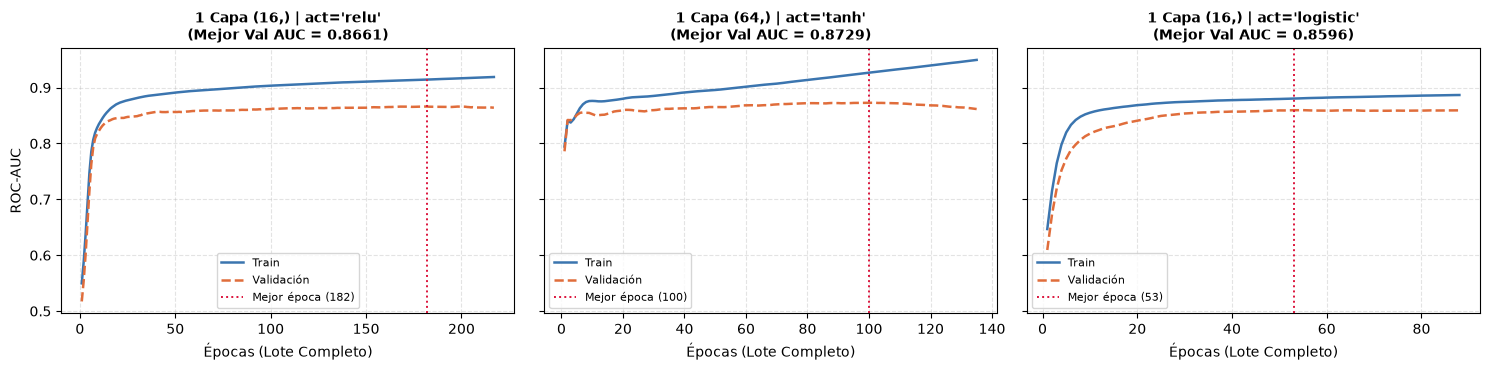

,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,"M7: MLP 1 Capa (64,) (tanh)",4. Red Neuronal (MLP),22,0.538,0.5632,0.0544,0.8658,0.8108,Todas (22)


In [117]:
neuronas_1c = [8, 16, 32, 64]
activaciones = ['relu', 'tanh', 'logistic']
experimentos_1c = []

for h in neuronas_1c:
    for act in activaciones:
        net, b_val, b_ep, h_tr, h_val = entrenar_mlp_batch((h,), act)
        experimentos_1c.append({
            'Arquitectura': f'({h},)',
            'Neuronas': h,
            'Activación': act,
            'Mejor_AUC_Val': round(b_val, 4),
            'Época_Óptima': b_ep,
            'Épocas_Totales': len(h_val),
            'hist_tr': h_tr,
            'hist_val': h_val
        })

df_1c = pd.DataFrame(experimentos_1c).sort_values(['Mejor_AUC_Val', 'Época_Óptima'], ascending=[False, True])
display(df_1c[['Arquitectura', 'Activación', 'Mejor_AUC_Val', 'Época_Óptima', 'Épocas_Totales']])

ganador_1c = df_1c.iloc[0]
print(f"Arquitectura 1 capa elegida: {ganador_1c['Arquitectura']} con activación '{ganador_1c['Activación']}' "
      f"(Val ROC-AUC = {ganador_1c['Mejor_AUC_Val']:.4f} en época {ganador_1c['Época_Óptima']})")

# Gráficas de evolución Train vs. Validación para el mejor modelo de cada función de activación
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, act in zip(axes, activaciones):
    sub_act = df_1c[df_1c['Activación'] == act].iloc[0]
    ep_axis = np.arange(1, len(sub_act['hist_tr']) + 1)
    ax.plot(ep_axis, sub_act['hist_tr'], label='Train', color='#3B75AF', linewidth=1.8)
    ax.plot(ep_axis, sub_act['hist_val'], label='Validación', color='#E06D3B', linestyle='--', linewidth=1.8)
    ax.axvline(sub_act['Época_Óptima'], color='crimson', linestyle=':', linewidth=1.4,
               label=f"Mejor época ({sub_act['Época_Óptima']})")
    ax.set_title(f"1 Capa {sub_act['Arquitectura']} | act='{act}'\n(Mejor Val AUC = {sub_act['Mejor_AUC_Val']:.4f})", fontweight='bold', fontsize=10)
    ax.set_xlabel('Épocas (Lote Completo)')
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.legend(fontsize=8)
axes[0].set_ylabel('ROC-AUC')
plt.tight_layout()
plt.show()

# Evaluación del MLP monocapa ganador en 5-Fold CV sobre X_train (sin tocar X_test)
h_opt_1c = int(ganador_1c['Neuronas'])
act_opt_1c = ganador_1c['Activación']
nombre_m7 = f"M7: MLP 1 Capa {ganador_1c['Arquitectura']} ({act_opt_1c})"

evaluar_cv_y_registrar(
    nombre_m7,
    '4. Red Neuronal (MLP)',
    FullBatchMLP(hidden_layer_sizes=(h_opt_1c,), activation=act_opt_1c, max_epochs=300, patience=35, lr=0.01),
    n_jobs=1
)
display(pd.DataFrame(resultados_cv[-1:]))

Podemos observar en las gráficas de evolución segun las epoch, que suelen todas tener un valor máximo de f2 similar, apreciandose incluso como se empieza a estar en terreno donde seguir un poco más ya estaría llevando a overfitting. A su vez remarcar que de momento es el modelo con mayor recall, preservando un buen AUC y F2-Score, a expensas de el accuracy. Contradiciendo una primera hipótesis que podría ser que frente a tener poca muestra, iba a haber una gran varianza en la red neuronal resultando en un ajuste sólido

### 4.3 MLP con Varias Capas Ocultas

Entrenamos y comparamos arquitecturas profundas variando el número de capas ocultas (2 y 3 capas en estructura piramidal: `(16, 8)`, `(32, 16)`, `(64, 32)` y `(32, 16, 8)`) y la función de activación (manteniendo la misma función en todas las capas ocultas de cada modelo), aplicando idéntico régimen de lote completo y parada temprana sobre validación.

,Arquitectura,Capas,Activación,Mejor_AUC_Val,Época_Óptima,Épocas_Totales
5,"(32, 16)",2,logistic,0.8761,148,183
11,"(32, 16, 8)",3,logistic,0.8746,146,181
7,"(64, 32)",2,tanh,0.8704,34,69
10,"(32, 16, 8)",3,tanh,0.8695,73,108
3,"(32, 16)",2,relu,0.8692,58,93
8,"(64, 32)",2,logistic,0.8670,125,160
2,"(16, 8)",2,logistic,0.8669,216,251
6,"(64, 32)",2,relu,0.8644,36,71
4,"(32, 16)",2,tanh,0.8632,35,70
1,"(16, 8)",2,tanh,0.8595,123,158


Arquitectura multicapa elegida: (32, 16) con activación 'logistic' (Val ROC-AUC = 0.8761 en época 148)


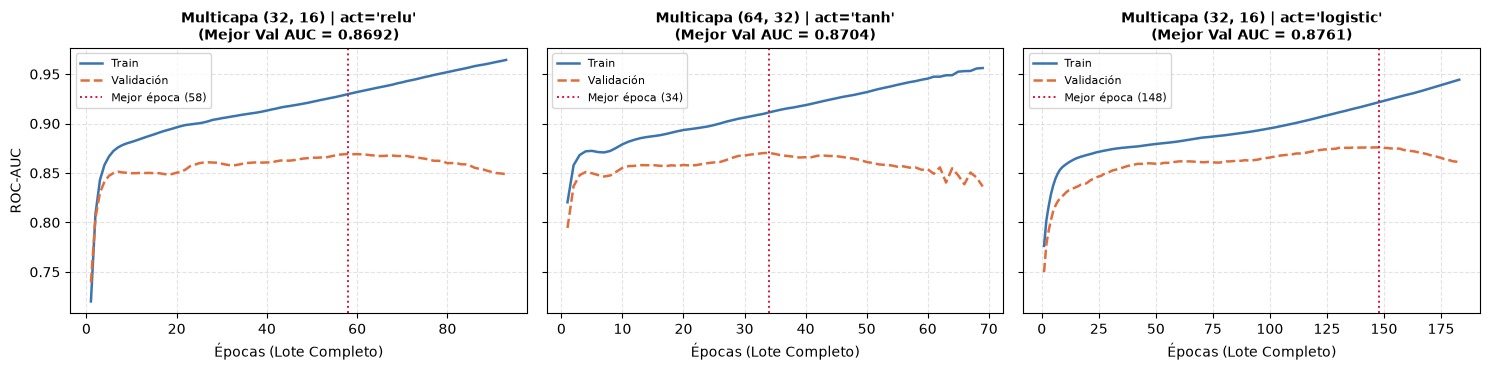

,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
0,"M7: MLP 1 Capa (64,) (tanh)",4. Red Neuronal (MLP),22,0.5380,0.5632,0.0544,0.8658,0.8108,Todas (22)
1,"M8: MLP Multicapa (32, 16) (logistic)",4. Red Neuronal (MLP),22,0.6135,0.6253,0.0216,0.8645,0.8142,Todas (22)


In [118]:
arquitecturas_mc = [(16, 8), (32, 16), (64, 32), (32, 16, 8)]
experimentos_mc = []

for arch in arquitecturas_mc:
    for act in activaciones:
        net, b_val, b_ep, h_tr, h_val = entrenar_mlp_batch(arch, act)
        experimentos_mc.append({
            'Arquitectura': str(arch),
            'arch_tuple': arch,
            'Capas': len(arch),
            'Activación': act,
            'Mejor_AUC_Val': round(b_val, 4),
            'Época_Óptima': b_ep,
            'Épocas_Totales': len(h_val),
            'hist_tr': h_tr,
            'hist_val': h_val
        })

df_mc = pd.DataFrame(experimentos_mc).sort_values(['Mejor_AUC_Val', 'Época_Óptima'], ascending=[False, True])
display(df_mc[['Arquitectura', 'Capas', 'Activación', 'Mejor_AUC_Val', 'Época_Óptima', 'Épocas_Totales']])

ganador_mc = df_mc.iloc[0]
print(f"Arquitectura multicapa elegida: {ganador_mc['Arquitectura']} con activación '{ganador_mc['Activación']}' "
      f"(Val ROC-AUC = {ganador_mc['Mejor_AUC_Val']:.4f} en época {ganador_mc['Época_Óptima']})")

# Gráficas de evolución Train vs. Validación para el mejor modelo multicapa de cada activación
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, act in zip(axes, activaciones):
    sub_act = df_mc[df_mc['Activación'] == act].iloc[0]
    ep_axis = np.arange(1, len(sub_act['hist_tr']) + 1)
    ax.plot(ep_axis, sub_act['hist_tr'], label='Train', color='#3B75AF', linewidth=1.8)
    ax.plot(ep_axis, sub_act['hist_val'], label='Validación', color='#E06D3B', linestyle='--', linewidth=1.8)
    ax.axvline(sub_act['Época_Óptima'], color='crimson', linestyle=':', linewidth=1.4,
               label=f"Mejor época ({sub_act['Época_Óptima']})")
    ax.set_title(f"Multicapa {sub_act['Arquitectura']} | act='{act}'\n(Mejor Val AUC = {sub_act['Mejor_AUC_Val']:.4f})", fontweight='bold', fontsize=10)
    ax.set_xlabel('Épocas (Lote Completo)')
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.legend(fontsize=8)
axes[0].set_ylabel('ROC-AUC')
plt.tight_layout()
plt.show()

# Evaluación del MLP multicapa ganador en 5-Fold CV sobre X_train (sin tocar X_test)
arch_opt_mc = ganador_mc['arch_tuple']
act_opt_mc = ganador_mc['Activación']
nombre_m8 = f"M8: MLP Multicapa {ganador_mc['Arquitectura']} ({act_opt_mc})"

evaluar_cv_y_registrar(
    nombre_m8,
    '4. Red Neuronal (MLP)',
    FullBatchMLP(hidden_layer_sizes=arch_opt_mc, activation=act_opt_mc, max_epochs=300, patience=35, lr=0.01),
    n_jobs=1
)
display(pd.DataFrame(resultados_cv[-2:]))

Podemos ahora observar en el MLP multicapa, como el F2-Score en CV tampoco cambia tanto respecto a SLP, resultando en ambos casos en ajustes sólidos, incluso algo peores que el SLP. Como curiosidad se puede observar como con función de activación sigmoide, necesita de más épocas para "converger", notando que el gradiente máximo de la sigmoide es 0.25, viendo como 'tanh' y 'relu' convergen en menos iteraciones, sobretodo en el caso de 'tanh'

### 4.4 Selección de Características mediante un MLP y Transferencia al Esquema Lineal

Utilizamos ahora un procedimiento *wrapper* de selección secuencial hacia adelante (*Forward SFS*) cuyo modelo de evaluación es el **MLP con la mejor configuración monocapa elegida**, realizando la selección exclusivamente sobre los subconjuntos internos de entrenamiento y validación (`X_tr_s` y `X_val_s`, ambos dentro de `X_train`, con aprendizaje por lote completo y parada temprana), sin tocar `X_test`.

Una vez obtenido el subconjunto de características más informativo para el MLP, evaluamos con esas mismas características un **esquema lineal (Regresión Logística)** mediante **`5-Fold CV` sobre `X_train`** y lo comparamos en CV frente a los modelos lineales de la Sección II (`M1`, `M2`, `M3`).

,k,Variable_Añadida,AUC_Val_MLP
0,1,Ratio_Gol_Tarjeta,0.8104
1,2,Gls,0.8247
2,3,Min_por_MP,0.8605
3,4,Tasa_Titular,0.8640
4,5,CrdY,0.8680
5,6,Starts,0.8713
6,7,Ast,0.8693
7,8,liga_es La Liga,0.8782
8,9,cambio_liga,0.8775
9,10,Gls_por_MP,0.8788


Óptimo Wrapper MLP en validación: k = 10 variables | Val ROC-AUC = 0.8788
Subconjunto seleccionado por el MLP: ['Ratio_Gol_Tarjeta', 'Gls', 'Min_por_MP', 'Tasa_Titular', 'CrdY', 'Starts', 'Ast', 'liga_es La Liga', 'cambio_liga', 'Gls_por_MP']


,Modelo,Familia,N_Vars,Recall (CV),F2-Score (CV),F2 std (CV),ROC-AUC (CV),Accuracy (CV),Variables
2,M1: Logística Sin Regularizar,2. Lineal,22,0.5379,0.5629,0.0370,0.8718,0.8085,Todas (22)
3,M2: Logística Regularizada (L1),2. Lineal,22,0.5337,0.5589,0.0331,0.8722,0.8073,Todas (22)
4,M3: Logística + Wrapper SFS (k=13),2. Lineal,13,0.5630,0.5868,0.0252,0.8685,0.8165,"Gls_por_MP, Min_por_MP, MP, Ratio_Gol_Tarjeta,..."
10,M9: Logística + Wrapper MLP (k=10),4. Híbrido (MLP -> Lineal),10,0.5127,0.5404,0.0332,0.8674,0.8050,"Ratio_Gol_Tarjeta, Gls, Min_por_MP, Tasa_Titul..."


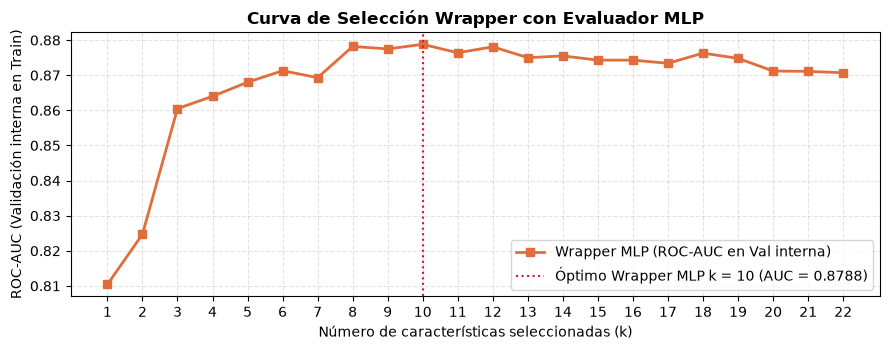

In [119]:
h_opt = int(ganador_1c['Neuronas'])
act_opt = ganador_1c['Activación']

restantes_idx = list(range(X_train.shape[1]))
seleccionadas_idx = []
curva_sfs_mlp = []

for paso in range(1, X_train.shape[1] + 1):
    mejor_i, mejor_sc = None, -1.0
    for i in restantes_idx:
        _, sc_val, _, _, _ = entrenar_mlp_batch(
            (h_opt,), act_opt, max_epochs=150, patience=25, cols_idx=seleccionadas_idx + [i]
        )
        if sc_val > mejor_sc:
            mejor_sc, mejor_i = sc_val, i
    seleccionadas_idx.append(mejor_i)
    restantes_idx.remove(mejor_i)
    cols_paso = [X_train.columns[j] for j in seleccionadas_idx]
    curva_sfs_mlp.append({
        'k': paso,
        'Variable_Añadida': X_train.columns[mejor_i],
        'AUC_Val_MLP': round(mejor_sc, 4),
        'Subconjunto': cols_paso
    })

df_sfs_mlp = pd.DataFrame(curva_sfs_mlp)
display(df_sfs_mlp[['k', 'Variable_Añadida', 'AUC_Val_MLP']])

fila_opt_mlp = df_sfs_mlp.loc[df_sfs_mlp['AUC_Val_MLP'].idxmax()]
cols_sfs_mlp = fila_opt_mlp['Subconjunto']
print(f"Óptimo Wrapper MLP en validación: k = {fila_opt_mlp['k']} variables | Val ROC-AUC = {fila_opt_mlp['AUC_Val_MLP']:.4f}")
print('Subconjunto seleccionado por el MLP:', cols_sfs_mlp)

# Evaluar esquema lineal (Regresión Logística) con las características seleccionadas por el MLP en 5-Fold CV (solo X_train)
evaluar_cv_y_registrar(f"M9: Logística + Wrapper MLP (k={len(cols_sfs_mlp)})", '4. Híbrido (MLP -> Lineal)',
                       pipe_lr_noreg, cols=cols_sfs_mlp)

# Comparativa directa en CV (Train) con los modelos lineales de la Sección II
df_res_all = pd.DataFrame(resultados_cv)
display(df_res_all[df_res_all['Familia'].str.contains('Lineal')])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(df_sfs_mlp['k'], df_sfs_mlp['AUC_Val_MLP'], marker='s', color='#E06D3B', linewidth=2,
        label='Wrapper MLP (ROC-AUC en Val interna)')
ax.axvline(fila_opt_mlp['k'], color='crimson', linestyle=':',
           label=f"Óptimo Wrapper MLP k = {fila_opt_mlp['k']} (AUC = {fila_opt_mlp['AUC_Val_MLP']:.4f})")
ax.set_xticks(df_sfs_mlp['k'])
ax.set_xlabel('Número de características seleccionadas (k)')
ax.set_ylabel('ROC-AUC (Validación interna en Train)')
ax.set_title('Curva de Selección Wrapper con Evaluador MLP', fontweight='bold')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

Antes que nada notar que al ser el método Forward Selection (Forward SFS), no garantiza que sea la mejor combinación. Una vez aclarado, podemos observar son features bastante similares a los métodos con feature selection de los modelos lineales, por lo que tenemos evidencia de que si que nos beneficia usar la no linealidad de las redes neuronales. La pregunta de que modelo escoger, reside principalmente en si quedarnos con la heurística que es sorpendentemente competitiva, los modelos lineales o el MLP unicapa

---
# 5. Comparación de Resultados en `X_train` Completo y Evaluación Final en Test (Sección IV)

### 5.1 Evaluación sobre `X_train` Completo de los Modelos Ya Entrenados con CV (Sin Tocar `X_test`)

Manteniendo intacto todo el entrenamiento, ajuste de hiperparámetros y selección de características realizados mediante **`5-Fold CV` sobre `X_train`** en las Secciones 2, 3 y 4, evaluamos ahora todos los modelos ya ajustados (`B0` a `M9`) sobre **`X_train` completo** ($n = 1.744$) en las cuatro figuras de mérito (`Recall`, `F2-Score`, `ROC-AUC`, `Accuracy`), mostrando también su `F2-Score (CV)` de validación, su complejidad e interpretabilidad. **`X_test` no se toca** hasta decidir el único modelo ganador.

,Modelo,Familia,Vars_Activas,Conjunto_Variables,Complejidad,Interpretabilidad,Recall (CV),F2-Score (CV),ROC-AUC (CV),Accuracy (CV)
0,B0: Dummy (Clase Mayoritaria),1. Baseline,22,Todas (22),1 (constante),Trivial,0.0000,0.0000,0.5000,0.7271
1,B1: Heurística (Gls_por_MP),1. Baseline,1,Gls_por_MP,1 (umbral),Muy alta (1 regla),0.8089,0.6887,0.7752,0.6571
2,M1: Logística Sin Regularizar,2. Lineal,22,Todas (22),23 pesos,Alta (Odds-Ratios),0.5379,0.5629,0.8718,0.8085
3,M2: Logística Regularizada (L1),2. Lineal,22,Todas (22),23 pesos,Alta (Odds-Ratios),0.5337,0.5589,0.8722,0.8073
4,M3: Logística + Wrapper SFS (k=13),2. Lineal,13,"Gls_por_MP, Min_por_MP, MP, Ratio_Gol_Tarjeta,...",14 pesos,Alta (Odds-Ratios),0.5630,0.5868,0.8685,0.8165
5,M4: Árbol de Decisión,3. Árboles,22,Todas (22),16 hojas (prof. 4),Alta (reglas árbol),0.5232,0.5436,0.8317,0.7913
6,M5: Random Forest,3. Árboles,22,Todas (22),150 árboles,Baja (ensamblado),0.5380,0.5638,0.8619,0.8113
7,M6: Gradient Boosting,3. Árboles,22,Todas (22),100 iter. boosting,Baja (ensamblado),0.5716,0.5868,0.8579,0.8027
8,"M7: MLP 1 Capa (64,) (tanh)",4. Red Neuronal (MLP),22,Todas (22),1537 parámetros,Nula (caja negra),0.5380,0.5632,0.8658,0.8108
9,"M8: MLP Multicapa (32, 16) (logistic)",4. Red Neuronal (MLP),22,Todas (22),1281 parámetros,Nula (caja negra),0.6135,0.6253,0.8645,0.8142


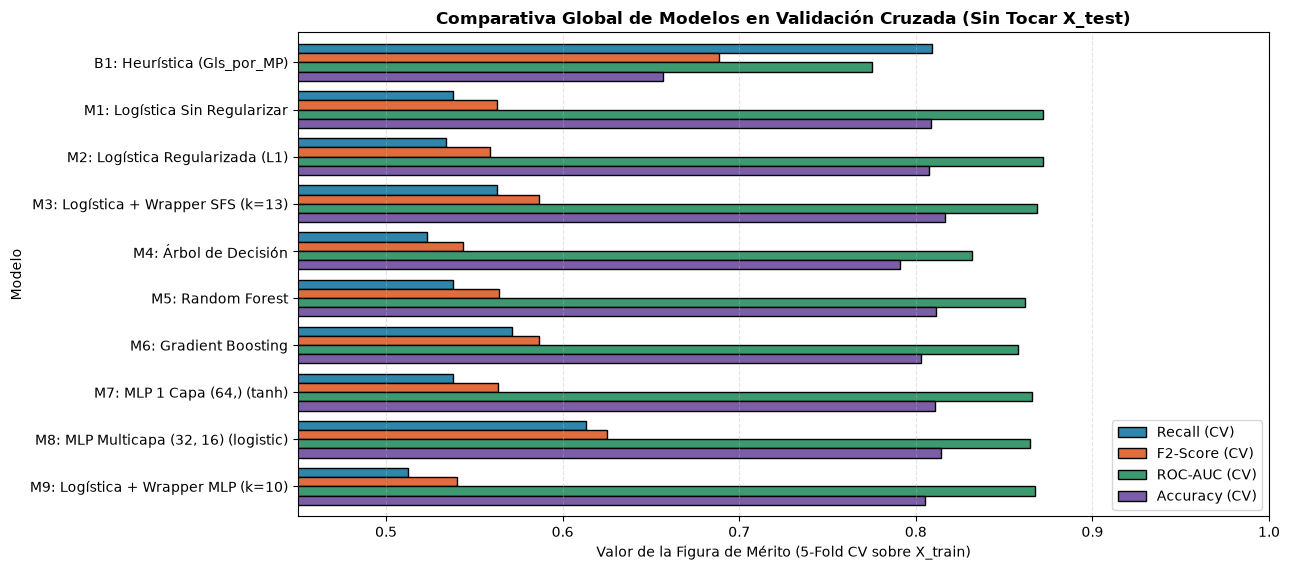

In [120]:
def _resumen_complejidad_e_interp(nombre, m_fit, cols_u):
    if nombre.startswith('B0'):
        return len(cols_u), '1 (constante)', 'Trivial'
    if nombre.startswith('B1'):
        return 1, '1 (umbral)', 'Muy alta (1 regla)'
    if 'Logística' in nombre:
        lr_step = m_fit.named_steps['lr']
        n_act = int(np.sum(np.abs(lr_step.coef_[0]) > 1e-4))
        return n_act, f'{n_act + 1} pesos', 'Alta (Odds-Ratios)'
    if 'Árbol' in nombre:
        return len(cols_u), f'{m_fit.get_n_leaves()} hojas (prof. {m_fit.get_depth()})', 'Alta (reglas árbol)'
    if 'Random Forest' in nombre:
        return len(cols_u), f'{m_fit.n_estimators} árboles', 'Baja (ensamblado)'
    if 'Gradient Boosting' in nombre:
        return len(cols_u), f'{m_fit.n_iter_} iter. boosting', 'Baja (ensamblado)'
    if 'MLP' in nombre:
        net = m_fit.best_net_
        n_params = sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_)
        return len(cols_u), f'{n_params} parámetros', 'Nula (caja negra)'
    return len(cols_u), '-', '-'


filas_cv_global = []
for fila_cv in resultados_cv:
    nombre = fila_cv['Modelo']
    _, cols_u, m_fit = modelos_registrados[nombre]
    n_act, comp_str, interp_str = _resumen_complejidad_e_interp(nombre, m_fit, cols_u)
    filas_cv_global.append({
        'Modelo': nombre,
        'Familia': fila_cv['Familia'],
        'Vars_Activas': n_act,
        'Conjunto_Variables': fila_cv['Variables'],
        'Complejidad': comp_str,
        'Interpretabilidad': interp_str,
        'Recall (CV)': fila_cv['Recall (CV)'],
        'F2-Score (CV)': fila_cv['F2-Score (CV)'],
        'ROC-AUC (CV)': fila_cv['ROC-AUC (CV)'],
        'Accuracy (CV)': fila_cv['Accuracy (CV)'],
    })

tabla_comparativa_cv = pd.DataFrame(filas_cv_global)
display(tabla_comparativa_cv)

# Comparación visual de las 4 figuras de mérito en 5-Fold CV (excluyendo B0 Dummy)
df_plot_cv = tabla_comparativa_cv.iloc[1:].set_index('Modelo')
metricas_cv = ['Recall (CV)', 'F2-Score (CV)', 'ROC-AUC (CV)', 'Accuracy (CV)']

ax = df_plot_cv[metricas_cv].plot(kind='barh', figsize=(13, 5.8), edgecolor='black', width=0.78,
                                  color=['#2E86AB', '#E06D3B', '#3D9970', '#7B5EA7'])
ax.set_xlim(0.45, 1.00)
ax.set_xlabel('Valor de la Figura de Mérito (5-Fold CV sobre X_train)')
ax.set_title('Comparativa Global de Modelos en Validación Cruzada (Sin Tocar X_test)', fontweight='bold')
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

#### Selección del Modelo Final (Criterios de Validación en `5-Fold CV`, sin tocar `X_test`)

A partir de la comparativa en validación cruzada estratificada de 5 pliegues (`tabla_comparativa_cv`), seleccionamos como modelo final la **heurística calibrada `B1: Heurística (Gls_por_MP)`** (conjunto de características: `['Gls_por_MP']`, regla única `Gls_por_MP >= 0.0429`). Esta decisión se fundamenta en tres criterios objetivos evaluados exclusivamente durante la validación:

1. **Prestaciones en las figuras de mérito prioritarias:**
   * En las dos métricas más relevantes para detectar perfiles ofensivos bajo desbalance de clases (`72,7%` clase `0` vs. `27,3%` clase `1`), la heurística **supera con un margen muy amplio a todos los modelos de aprendizaje automático evaluados**: alcanza un **`Recall` de `0.8089`** y un **`F2-Score` de `0.6887`**.
   * En contraste, tanto los modelos lineales (`M1`–`M3`, `M9`) como los métodos basados en árboles (`M4`–`M6`) y las redes neuronales (`M7`–`M8`), operando con el umbral estándar (`0.50`), obtienen un `Recall` claramente insuficiente (`0.5127–0.6135`, dejando sin detectar cerca del 40–45% de los jugadores ofensivos) y un `F2-Score` notablemente inferior (`0.5404–0.6253`).
   * Su capacidad discriminativa (`ROC-AUC = 0.7752`) es muy notable tratándose de una única característica. Aunque su `Accuracy` (`0.6571`) es menor que la de los modelos lineales o ensamblados (`~0.80–0.82`) debido a una mayor tasa de falsos positivos, ante el desbalance existente y el objetivo de no perder perfiles ofensivos resulta preferible asumir esa pérdida de exactitud global frente a modelos mucho más complejos con un `Recall` muy bajo.

2. **Complejidad y comportamiento de varianza:**
   * Con un tamaño muestral moderado ($n_{\text{train}} = 1.744$ observaciones, una única fila agregada por jugador) y un conjunto limitado de estadísticas ofensivas, los modelos de mayor capacidad no aportan ventajas acordes a su coste. En particular, las curvas de evolución por época de los MLP muestran claramente cómo el rendimiento en entrenamiento continúa creciendo mientras el de validación se estanca o cae, reflejando **alta varianza y propensión al sobreajuste**.
   * Recurrir a ensamblados de árboles o redes neuronales con más de mil parámetros para un problema cuya señal principal reside en el volumen goleador supone una complejidad innecesaria (*principio de parsimonia*).

3. **Interpretabilidad y coste operativo:**
   * Frente a modelos de caja negra (MLP, Random Forest, Gradient Boosting), `B1` posee **interpretabilidad inmediata** y coste computacional despreciable: un único parámetro (umbral sobre goles por partido) directamente traducible a una consulta SQL.

**Distinción validación vs. evaluación final:** toda la comparación y elección anterior se ha realizado sin observar `X_test`. A continuación, aplicamos **únicamente el modelo elegido (`B1`)** una sola vez sobre el conjunto de test reservado (`X_test`) para estimar de forma imparcial su capacidad de generalización fuera de muestra.

Modelo evaluado en Test : B1: Heurística (Gls_por_MP)
Regla fijada en Train   : Gls_por_MP >= 0.0429 (n_test = 437)


,Recall,F2-Score,ROC-AUC,Accuracy
Evaluación,,,,
Validación (5-Fold CV en X_train),0.8089,0.6887,0.7752,0.6571
Evaluación Final (X_test reservado),0.8571,0.7255,0.7900,0.6751


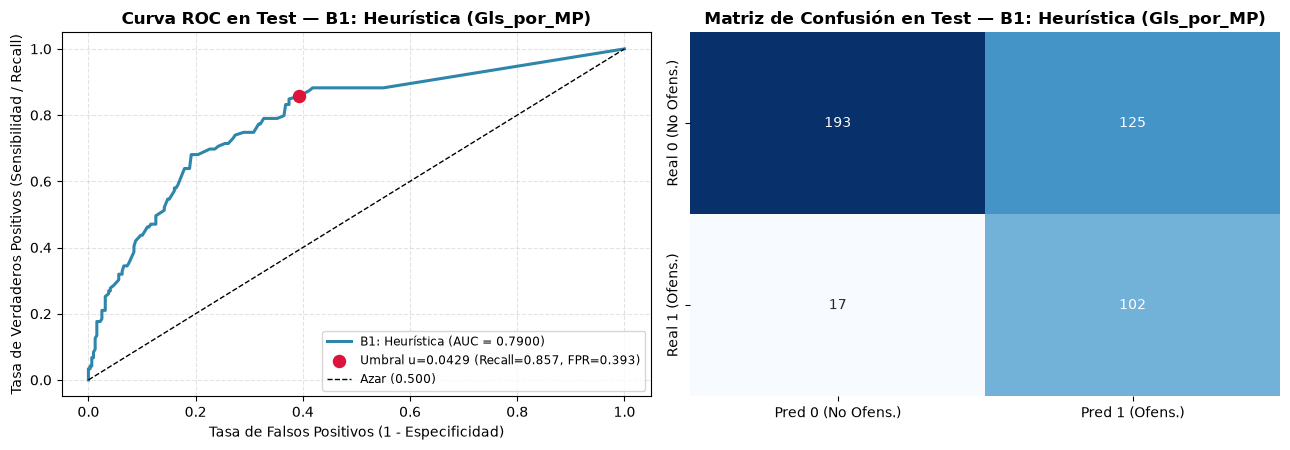

In [121]:
# Evaluación final única sobre el conjunto de test reservado (X_test, y_test)
# Aplicamos EXCLUSIVAMENTE el modelo elegido en validación: B1: Heurística (Gls_por_MP)
_, cols_b1, m_fit_b1 = modelos_registrados[nombre_h]
fila_cv_b1 = next(f for f in resultados_cv if f['Modelo'] == nombre_h)

y_pred_te = m_fit_b1.predict(X_test[cols_b1])
y_prob_te = m_fit_b1.predict_proba(X_test[cols_b1])[:, 1]

rec_te = recall_score(y_test, y_pred_te, zero_division=0)
f2_te  = fbeta_score(y_test, y_pred_te, beta=2, zero_division=0)
auc_te = roc_auc_score(y_test, y_prob_te)
acc_te = accuracy_score(y_test, y_pred_te)

print(f"Modelo evaluado en Test : {nombre_h}")
print(f"Regla fijada en Train   : Gls_por_MP >= {m_fit_b1.mejor_u_:.4f} (n_test = {len(X_test)})")

resumen_test_b1 = pd.DataFrame([
    {
        'Evaluación': 'Validación (5-Fold CV en X_train)',
        'Recall': fila_cv_b1['Recall (CV)'],
        'F2-Score': fila_cv_b1['F2-Score (CV)'],
        'ROC-AUC': fila_cv_b1['ROC-AUC (CV)'],
        'Accuracy': fila_cv_b1['Accuracy (CV)'],
    },
    {
        'Evaluación': 'Evaluación Final (X_test reservado)',
        'Recall': round(rec_te, 4),
        'F2-Score': round(f2_te, 4),
        'ROC-AUC': round(auc_te, 4),
        'Accuracy': round(acc_te, 4),
    }
]).set_index('Evaluación')
display(resumen_test_b1)

# Gráficos en X_test: Curva ROC (con punto de operación) y Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_te)
tn, fp, fn, tp = cm.ravel()
fpr_op = fp / (fp + tn)
tpr_op = tp / (tp + fn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

fpr, tpr, _ = roc_curve(y_test, y_prob_te)
axes[0].plot(fpr, tpr, color='#2E86AB', linewidth=2.2, label=f'B1: Heurística (AUC = {auc_te:.4f})')
axes[0].scatter([fpr_op], [tpr_op], color='crimson', s=75, zorder=5,
                label=f'Umbral u={m_fit_b1.mejor_u_:.4f} (Recall={tpr_op:.3f}, FPR={fpr_op:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Azar (0.500)')
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)')
axes[0].set_title('Curva ROC en Test — B1: Heurística (Gls_por_MP)', fontweight='bold')
axes[0].legend(fontsize=8.5, loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.35)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Pred 0 (No Ofens.)', 'Pred 1 (Ofens.)'],
            yticklabels=['Real 0 (No Ofens.)', 'Real 1 (Ofens.)'])
axes[1].set_title('Matriz de Confusión en Test — B1: Heurística (Gls_por_MP)', fontweight='bold')
plt.tight_layout()
plt.show()

#### Conclusiones de la Evaluación Final en Test, Limitaciones y Líneas de Mejora Futuras

* **Conclusiones sobre `X_test` (generalización fuera de muestra):**
  * La evaluación final única sobre el conjunto de test reservado ($n = 437$ jugadores no vistos) confirma plenamente lo observado en validación cruzada: `B1: Heurística (Gls_por_MP)` obtiene **`Recall = 0.8571`**, **`F2-Score = 0.7255`**, **`ROC-AUC = 0.7900`** y **`Accuracy = 0.6751`** (valores incluso ligeramente superiores a los de `5-Fold CV`, lo que descarta sobreajuste en la calibración del umbral `Gls_por_MP >= 0.0429`).
  * La matriz de confusión refleja claramente el compromiso asumido: la regla detecta correctamente a la gran mayoría de los perfiles ofensivos reales (`102` de `119`), concentrando sus errores principalmente en falsos positivos (centrocampistas llegadores o defensas con aportación goleadora puntual).

* **Limitaciones del planteamiento actual:**
  * El hecho de que una regla univariante basada en goles por partido supere en `Recall` y `F2-Score` a modelos lineales, árboles y redes neuronales pone de manifiesto una **limitación estructural del conjunto de datos**: al disponer únicamente de conteos agregados básicos de temporada (goles, asistencias, minutos y tarjetas), casi toda la señal discriminativa recae sobre el gol, reduciendo el problema a una frontera muy sencilla donde los modelos más complejos no disponen de información adicional suficiente para justificar su varianza.
  * Además, definir el objetivo únicamente a partir de la demarcación nominal (`Pos`) y predecirlo con goles deja sin capturar perfiles ofensivos de perfil asociativo o generador que no acumulan cifras altas de anotación.

* **Propuestas de mejora y trabajo futuro:**
  1. **Métricas de creación, volumen y eficacia ofensiva:** incorporar variables por partido o por 90 minutos como **regates intentados y completados**, **tiros intentados y a puerta** (para separar volumen de finalización frente a acierto goleador), **pases intentados, pases progresivos y pases clave**, así como **participación en secuencias ofensivas que terminan en tiro o gol** (*shot-creating actions*, *goal-creating actions*, *xG* y *xA*).
  2. **Caracterización espacial del juego por zonas del campo:** segmentar el terreno de juego en zonas (campo propio / tercio defensivo, zona de creación y campo rival / último tercio) para cuantificar qué proporción del tiempo, de los toques o de las acciones desarrolla cada jugador en **zona rival frente a zona de su propio equipo**. Este tipo de métricas territoriales permitiría identificar con mucho mayor rigor el **perfil táctico ofensivo real** de un futbolista (incluyendo carrileros muy profundos o interiores ofensivos), independientemente de si su posición nominal es la de delantero o de cuántos goles haya marcado.
  3. **Calibración de umbral en esquemas probabilísticos:** si en un escenario futuro se necesitara mayor especificidad (menos falsos positivos) sin renunciar a un *Recall* elevado, una extensión natural sería ajustar el umbral de decisión (o aplicar pesos asimétricos a los errores) sobre la **Regresión Logística**, aprovechando su mayor `ROC-AUC` en validación (`~0.87`) manteniendo plena interpretabilidad.

#### Comparativa Global de Todos los Modelos en `X_test` (Verificación *Post-Hoc*)

Desde un punto de vista metodológico estricto, comparar múltiples modelos sobre el conjunto de test para decidir entre ellos introduciría fuga de información en la selección (*selection leakage*), comprometiendo el papel de `X_test` como estimador imparcial del comportamiento en producción. Por ese motivo, **todas las decisiones de diseño y la elección del modelo final (`B1`) se cerraron exclusivamente mediante validación cruzada (`5-Fold CV`)** en los apartados anteriores.

No obstante, dado que el guion solicita explícitamente presentar una tabla comparativa de todos los modelos desarrollados evaluados sobre el mismo conjunto de test reservado, se incluye a continuación dicha comparativa global sobre `X_test` únicamente como **auditoría final *post-hoc*** (sin modificar ninguna decisión tomada en validación), comprobando que las diferencias relativas observadas en CV se mantienen fuera de muestra.

,Modelo,Familia,Vars_Activas,Conjunto_Variables,Complejidad,Interpretabilidad,Recall (Test),F2-Score (Test),ROC-AUC (Test),Accuracy (Test),F2-Score (CV)
0,B0: Dummy (Clase Mayoritaria),1. Baseline,22,Todas (22),1 (constante),Trivial,0.0000,0.0000,0.5000,0.7277,0.0000
1,B1: Heurística (Gls_por_MP),1. Baseline,1,Gls_por_MP,1 (umbral),Muy alta (1 regla),0.8571,0.7255,0.7900,0.6751,0.6887
2,M1: Logística Sin Regularizar,2. Lineal,22,Todas (22),23 pesos,Alta (Odds-Ratios),0.6218,0.6379,0.9001,0.8284,0.5629
3,M2: Logística Regularizada (L1),2. Lineal,22,Todas (22),23 pesos,Alta (Odds-Ratios),0.6218,0.6379,0.9000,0.8284,0.5589
4,M3: Logística + Wrapper SFS (k=13),2. Lineal,13,"Gls_por_MP, Min_por_MP, MP, Ratio_Gol_Tarjeta,...",14 pesos,Alta (Odds-Ratios),0.6050,0.6218,0.8925,0.8215,0.5868
5,M4: Árbol de Decisión,3. Árboles,22,Todas (22),16 hojas (prof. 4),Alta (reglas árbol),0.5042,0.5357,0.8589,0.8101,0.5436
6,M5: Random Forest,3. Árboles,22,Todas (22),150 árboles,Baja (ensamblado),0.5966,0.6228,0.8905,0.8375,0.5638
7,M6: Gradient Boosting,3. Árboles,22,Todas (22),100 iter. boosting,Baja (ensamblado),0.5714,0.5965,0.8883,0.8238,0.5868
8,"M7: MLP 1 Capa (64,) (tanh)",4. Red Neuronal (MLP),22,Todas (22),1537 parámetros,Nula (caja negra),0.6218,0.6282,0.8807,0.8078,0.5632
9,"M8: MLP Multicapa (32, 16) (logistic)",4. Red Neuronal (MLP),22,Todas (22),1281 parámetros,Nula (caja negra),0.6555,0.6599,0.8805,0.8215,0.6253


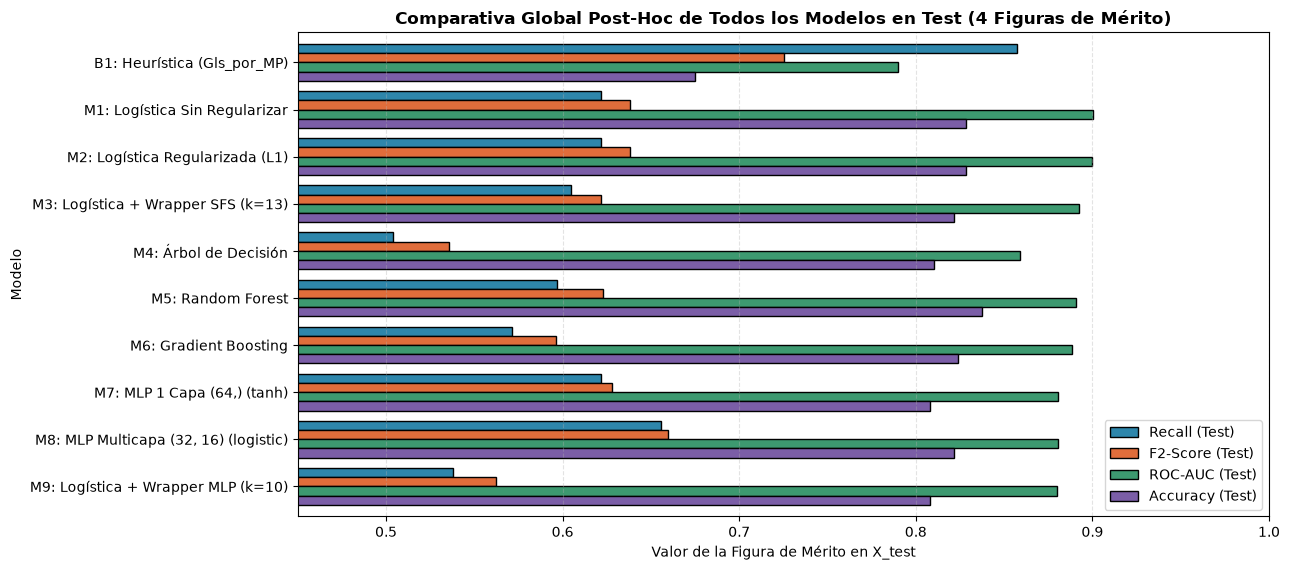

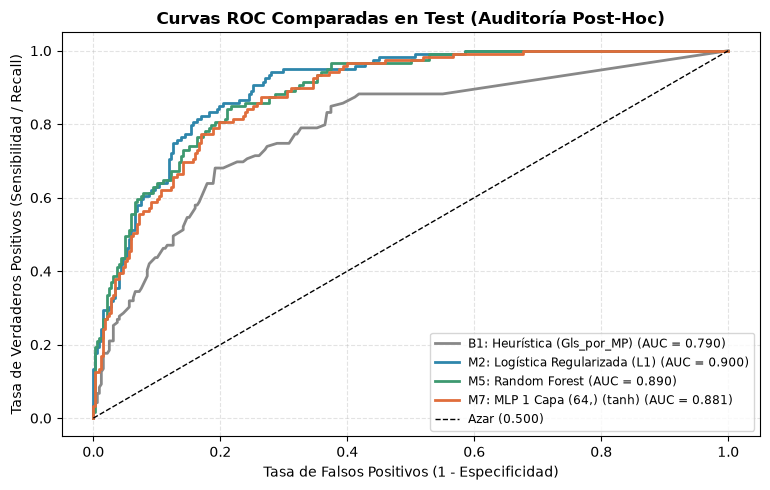

In [122]:
# Auditoría final post-hoc: comparativa de todos los modelos sobre el mismo X_test reservado
# (No se emplea para re-seleccionar modelos ni hiperparámetros; la elección de B1 se cerró en 5-Fold CV)
resultados_test_todos = []
predicciones_test_todos = {}

for fila_cv in resultados_cv:
    nombre = fila_cv['Modelo']
    _, cols_u, m_fit = modelos_registrados[nombre]

    yp_te  = m_fit.predict(X_test[cols_u])
    ypr_te = m_fit.predict_proba(X_test[cols_u])[:, 1]
    n_act, comp_str, interp_str = _resumen_complejidad_e_interp(nombre, m_fit, cols_u)

    resultados_test_todos.append({
        'Modelo': nombre,
        'Familia': fila_cv['Familia'],
        'Vars_Activas': n_act,
        'Conjunto_Variables': fila_cv['Variables'],
        'Complejidad': comp_str,
        'Interpretabilidad': interp_str,
        'Recall (Test)': round(recall_score(y_test, yp_te, zero_division=0), 4),
        'F2-Score (Test)': round(fbeta_score(y_test, yp_te, beta=2, zero_division=0), 4),
        'ROC-AUC (Test)': round(roc_auc_score(y_test, ypr_te), 4),
        'Accuracy (Test)': round(accuracy_score(y_test, yp_te), 4),
        'F2-Score (CV)': fila_cv['F2-Score (CV)'],
    })
    predicciones_test_todos[nombre] = (yp_te, ypr_te)

tabla_comparativa_test = pd.DataFrame(resultados_test_todos)
display(tabla_comparativa_test)

# 1. Gráfica comparativa de las 4 figuras de mérito en X_test (excluyendo B0 Dummy)
df_plot_te = tabla_comparativa_test.iloc[1:].set_index('Modelo')
metricas_te = ['Recall (Test)', 'F2-Score (Test)', 'ROC-AUC (Test)', 'Accuracy (Test)']

ax = df_plot_te[metricas_te].plot(kind='barh', figsize=(13, 5.8), edgecolor='black', width=0.78,
                                  color=['#2E86AB', '#E06D3B', '#3D9970', '#7B5EA7'])
ax.set_xlim(0.45, 1.00)
ax.set_xlabel('Valor de la Figura de Mérito en X_test')
ax.set_title('Comparativa Global Post-Hoc de Todos los Modelos en Test (4 Figuras de Mérito)', fontweight='bold')
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

# 2. Curvas ROC comparadas en X_test de representantes por familia
representantes = [
    nombre_h,
    'M2: Logística Regularizada (L1)',
    'M5: Random Forest',
    nombre_m7
]
colores_roc = ['#888888', '#2E86AB', '#3D9970', '#E06D3B']

fig, ax = plt.subplots(figsize=(7.8, 5.0))
for nom, col_r in zip(representantes, colores_roc):
    _, ypr_r = predicciones_test_todos[nom]
    fpr_r, tpr_r, _ = roc_curve(y_test, ypr_r)
    auc_v = roc_auc_score(y_test, ypr_r)
    ax.plot(fpr_r, tpr_r, label=f'{nom} (AUC = {auc_v:.3f})', color=col_r, linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Azar (0.500)')
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)')
ax.set_title('Curvas ROC Comparadas en Test (Auditoría Post-Hoc)', fontweight='bold')
ax.legend(fontsize=8.5, loc='lower right')
ax.grid(True, linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

### 5.2 Procedimiento para Obtener Estadísticos (Media y Desviación Típica) sobre Test

*(Nota: conforme a las instrucciones del guion, este apartado se desarrolla exclusivamente de forma teórica y metodológica, sin implementarse en código).*

Evaluar los modelos sobre una única partición fija de test (`X_test`, $20\%$) proporciona una **estimación puntual** de cada una de las cuatro figuras de mérito (`Recall`, `F2-Score`, `ROC-AUC`, `Accuracy`), pero no cuantifica la **incertidumbre o variabilidad muestral** asociada a qué jugadores concretos cayeron por azar en test. Para obtener estadísticos robustos —como la **media ($\hat{\mu}$)** y la **desviación típica ($\hat{\sigma}$)**— sobre test sin cometer fuga de información (*data leakage*), el procedimiento riguroso es la **Validación Cruzada Anidada Estratificada Repetida (*Repeated Stratified Nested Cross-Validation*)**:

1. **Bucle Externo (*Outer Loop* — Partición de Evaluación en Test):**
   * Se divide el conjunto de datos completo consolidado ($N = 2.181$ jugadores) mediante un esquema de **$K_{\text{ext}}$ pliegues estratificados repetido $R$ veces** (por ejemplo, $K_{\text{ext}} = 5$ pliegues con $R = 2$ o $R = 5$ repeticiones con distintas semillas, generando $M = R \times K_{\text{ext}}$ iteraciones externas independientes).
   * En cada iteración externa $m \in \{1, \dots, M\}$, un pliegue ($20\%$) queda estrictamente aislado como **conjunto de test externo $\mathcal{D}_{\text{test}}^{(m)}$**, y el $80\%$ restante forma el **conjunto de diseño $\mathcal{D}_{\text{train}}^{(m)}$**.

2. **Bucle Interno (*Inner Loop* — Preprocesamiento, Selección y Ajuste en Validación):**
   * Dentro de cada iteración $m$, utilizando **exclusivamente $\mathcal{D}_{\text{train}}^{(m)}$**, se ejecuta desde cero todo el flujo de diseño:
     1. Ajuste de transformadores que dependen de los datos (`StandardScaler` ajustado solo sobre $\mathcal{D}_{\text{train}}^{(m)}$).
     2. Selección de características mediante los métodos *wrapper* (SFS lineal y SFS con MLP).
     3. Selección de hiperparámetros (`C` en regularización $L_1$, profundidad en árboles, arquitectura y época de parada temprana del MLP) mediante validación cruzada interna ($K_{\text{int}} = 5$ pliegues) o partición interna de validación sobre $\mathcal{D}_{\text{train}}^{(m)}$.

3. **Evaluación Externa y Cálculo de Estadísticos ($\hat{\mu} \pm \hat{\sigma}$):**
   * El modelo óptimo entrenado en la iteración $m$ se evalúa una sola vez sobre su partición reservada $\mathcal{D}_{\text{test}}^{(m)}$, obteniendo para cada figura de mérito $j \in \{\text{Recall}, \text{F2}, \text{ROC\_AUC}, \text{Acc}\}$ una realización $S_j^{(m)}$.
   * Al completar las $M$ iteraciones externas, se dispone de $M$ evaluaciones en test libres de sesgo $\{S_j^{(1)}, S_j^{(2)}, \dots, S_j^{(M)}\}$, sobre las que se calculan la media y la desviación típica muestral de cada figura de mérito:
     $$\hat{\mu}_j = \frac{1}{M} \sum_{m=1}^{M} S_j^{(m)}, \qquad \hat{\sigma}_j = \sqrt{\frac{1}{M - 1} \sum_{m=1}^{M} \left(S_j^{(m)} - \hat{\mu}_j\right)^2}$$
   * *(Alternativa complementaria si el conjunto de test debe permanecer único y fijo: aplicar **Bootstrapping no paramétrico sobre $\mathcal{D}_{\text{test}}$**, generando $B = 1.000$ muestras de tamaño $n_{\text{test}}$ extraídas con reemplazamiento de `X_test, y_test`, evaluando el modelo fijo en cada réplica bootstrap $b = 1, \dots, B$ y calculando la media y desviación típica bootstrap de las 4 métricas).*